<a href="https://colab.research.google.com/github/kyawpyaepyaemoe/mango_xds/blob/main/Mango_Leaf_Disease_Classification_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable Mango Leaf Disease Classification — v3
### Does Grad-CAM tell a field officer the truth about a ResNet-50?

**Course:** AST02.903 Explainable Data Science (AIT) · **Dataset:** MangoLeafBD (8 classes × 500 images)

---

**Audience and decision (Criterion 1).** A provincial agricultural **field officer** receives leaf photos sent in by farmers and must decide **which farms to visit first this week**.
For each photo the system shows (1) a disease label, (2) a triage tier, (3) a Grad-CAM heat map, and (4) an *accept / retake / expert-review* flag.
If the officer trusts a wrong "Low"/"None" label, a farm with Anthracnose or Die Back waits for a visit and the disease spreads; if they trust a wrong "High", a visit is wasted on a healthy orchard.
The heat map is only useful if it helps the officer **notice when the label is wrong** — that is the property every section below tests.

**Central claim under test:** *Grad-CAM heat maps are a trustworthy account of what this ResNet-50 uses to make its prediction.*
The notebook reports evidence for **and against** this claim. Section 17 collects the numbers into one verdict table.

### What changed from v1

| v1 problem | v2 fix | Section |
|---|---|---|
| Timestamp key found 3,671 groups from 4,000 images, so most copies still crossed the split | Visual near-duplicate grouping (rotation-invariant ImageNet embeddings) ∪ timestamp key; leak audit of the old split | §2 |
| Grad-CAM ≈ edge-detector null on deletion; loses on plausibility — not discussed | Paired per-image comparisons with bootstrap CIs, two deletion baselines, automatic verdicts | §7, §8.1 |
| No white-box / synthetic check | Planted-patch shortcut with known ground truth; background-reliance faithfulness test | §8.3, §8.4 |
| Seed agreement not compared to its control | Agreement normalised against shuffled control; determinism check | §9 |
| Grey background is also OOD | Same-class vs cross-class background swap separates artefact from shortcut | §10 |
| OOD test used noise/solid colours; T hit grid edge; real non-mango leaves accepted at 0.9999 | Real other-plant leaves, kNN feature-distance score, thresholds fixed on validation | §11 |
| "Counterfactual" = blurring 40% of pixels | Minimal **photo-condition** counterfactual (mutable: light, focus, compression, background) | §12 |
| Human study measured liking of heat maps | Error-detection study: with vs without Grad-CAM, counterbalanced forms | §15 |
| Dangling references (§7.3 kit, §5 sensitivity), empty cell, `%%` labels, Windows path | Fixed / implemented | throughout |

### What changed from v2 (after the first full run)

| v2 result | v3 fix | Section |
|---|---|---|
| The planted square flipped only 0.2% of diseased leaves: Healthy was already perfectly separable, so the model never needed the square | The square is stamped on 10% of **diseased** training leaves, which are labelled Healthy, so the square is the only way to fit them | §8.4 |
| Temperature hit the grid edge (T = 0.05, confidence 1.0 on everything) and the accept flag rejected 97.5% of field-condition photos | Temperature and thresholds are fitted on validation photos that are clean **and** field-degraded; acceptance is reported per photo type | §11 |
| The counterfactual result was driven by the accept flag (best single fix rescued 3%) | Extra table showing which requirement fails: the accept flag or the tier | §12 |
| The clean test set has no errors, so the tier metrics said nothing | A note is printed; the missed-high rate under field conditions is in the verdict table | §5, §17 |
| The grouping threshold was chosen with the instructor's ~1,800 as a prior | Leakage check repeated one threshold step either side; larger montages | §2 |
| Wrong and right study cases could come from different kinds of photo | Cases are balanced across the two photo sources | §15 |
| Model card said 25.6M parameters; "Run all" stopped at the upload demo | 23.5M; the demo is opt-in | §19, §20 |

The code was also simplified (shared helpers for repeated steps); numbers not listed above are unchanged from v2.

### How to run
* **Colab (GPU):** Runtime → Run all. Outputs go to `MyDrive/XDS/mango_outputs_v2`.
* **Local / one command:** `pip install -r requirements.txt && papermill Mango_Leaf_Disease_Classification_v3.ipynb out.ipynb` (the config cell is tagged `parameters`). Every run writes the pinned `requirements.txt` to the output folder; **commit a copy at the repository root**.
* `MANGO_QUICK=1` runs a tiny CPU smoke test (~48 images per class, 1 epoch). Full GPU run (T4) ≈ 45–60 min, mostly training 3 seeds + the planted-patch model. Checkpoints from the v2 run are reused (same split); only the planted-patch model is retrained.

In [ ]:
# ===== Environment setup (works in Colab and locally) =====
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "opencv-python-headless", "kagglehub", "grad-cam", "papermill"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("MANGO_OUT", "/content/drive/MyDrive/XDS/mango_outputs_v2")
    # optional: a zip of the dataset on Drive (otherwise kagglehub downloads it)
    ZIP = "/content/drive/MyDrive/XDS/MangoLeafBD Dataset.zip"
    if os.path.exists(ZIP) and not os.path.exists("/content/mango"):
        subprocess.run(["unzip", "-q", ZIP, "-d", "/content/mango"], check=True)
    if os.path.exists("/content/mango"):
        os.environ.setdefault("MANGO_ROOT", "/content/mango")

os.environ.setdefault("MANGO_QUICK", "0")
# must be set before CUDA initialises (deterministic cuBLAS)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
print("Colab:", IN_COLAB, "| quick:", os.environ["MANGO_QUICK"])

Mounted at /content/drive
Colab: True | quick: 0


In [ ]:
import os, random, re, time, copy, warnings, itertools, hashlib
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import cv2

import torch, torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, StratifiedShuffleSplit
from sklearn.cluster import AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score,
)

warnings.filterwarnings("ignore")

# ======================= CONFIG (papermill parameters) =======================
QUICK_MODE = os.environ.get("MANGO_QUICK", "0") == "1"
IMG        = int(os.environ.get("MANGO_IMG", 256))
EPOCHS     = 1 if QUICK_MODE else 12
SEEDS      = [0, 1] if QUICK_MODE else [0, 1, 2]
BATCH      = 32
LR_BACK    = 1e-4
LR_HEAD    = 1e-3
N_FAITH    = 6 if QUICK_MODE else 200     # images for deletion/insertion
N_STAB     = 6 if QUICK_MODE else 60      # images for stability
N_CF       = 8 if QUICK_MODE else 150     # images for photo-condition counterfactuals
SPLIT_SEED = 42
REUSE_CKPT = True

# near-duplicate grouping (§2)
EXPECTED_DISTINCT = 1800   # instructor feedback: ~1,800 distinct leaves in 4,000 photos
DUP_THR    = None          # cosine distance; None = choose by rule in §2 and CHECK THE MONTAGES

# planted-patch white-box check (§8.4)
PATCH_CLASS  = "Healthy"
PATCH_FRAC   = 0.10        # share of DISEASED training images that get the square AND the label PATCH_CLASS
PATCH_EPOCHS = 1 if QUICK_MODE else 6

# OOD (§11): folder of non-mango leaf photos, or a Kaggle dataset slug to sample from
OOD_DIR    = os.environ.get("MANGO_OOD_DIR", "")
OOD_KAGGLE = "emmarex/plantdisease"   # PlantVillage (pepper/potato/tomato leaves)
N_OOD      = 20 if QUICK_MODE else 300
# =============================================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

OUT = Path(os.environ.get("MANGO_OUT", "outputs_quick" if QUICK_MODE else "outputs_v2"))
for sub_dir in ["ckpt", "figs", "tables"]:
    (OUT / sub_dir).mkdir(parents=True, exist_ok=True)

# ----- SEED REGISTRY (every random seed in this notebook) -----
# SPLIT_SEED = 42          data split
# set_seed(0/1/2)          ResNet training (per SEEDS); patched model uses seed 0
# default_rng(0)           quick-mode subsample, LR bootstrap, null maps, paired bootstrap
# default_rng(3)           Grad-CAM gallery
# default_rng(5)           plausibility panel
# default_rng(7)           faithfulness image selection
# default_rng(11)          annotation-kit selection
# default_rng(13)          planted-patch locations (train) / (17) test
# default_rng(21)          stability perturbations
# default_rng(31)          background-swap donors
# default_rng(41)          field-shift generation (test photos) / (43) calibration photos (validation)
# default_rng(51)          OOD sampling
# default_rng(61)          counterfactual photo conditions
# default_rng(77)          human-study case selection
# torch.manual_seed(123)   cascading randomisation


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


set_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
IMG_EXT = (".jpg", ".jpeg", ".png")


# ----- small helpers used in every section -----
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / "figs" / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


def show(ax, img=None, title=None, fontsize=7, **kw):
    """Draw an image on an axis without ticks; img=None leaves an empty panel."""
    ax.axis("off")
    if img is not None:
        ax.imshow(img, **kw)
    if title is not None:
        ax.set_title(title, fontsize=fontsize)


def load_rgb(path):
    return cv2.resize(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB), (IMG, IMG))


def to_gray(img):
    return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def dilate(mask, k):
    return cv2.dilate(mask.astype(np.uint8), np.ones((k, k), np.uint8)).astype(bool)


def norm01(m):
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


print("device:", DEVICE, "| quick:", QUICK_MODE, "| out:", OUT)

device: cuda | quick: False | out: /content/drive/MyDrive/XDS/mango_outputs_v2


In [ ]:
# ----- Pin dependency versions (Criterion 9) -----
from importlib.metadata import version, PackageNotFoundError

pkgs = ["torch", "torchvision", "opencv-python-headless", "numpy", "pandas",
        "scikit-learn", "scipy", "matplotlib", "grad-cam", "kagglehub", "papermill"]
lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={version(p).split('+')[0]}")   # drop local tags like +cu130 so pip can resolve it
    except PackageNotFoundError:
        lines.append(f"# {p} not installed")
req_text = "\n".join(lines)
(OUT / "requirements.txt").write_text(req_text + "\n")
print(req_text)

torch==2.14.1
torchvision==0.29.1
opencv-python-headless==5.0.0.93
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
grad-cam==1.5.7
kagglehub==1.0.3
papermill==2.7.0


---
## 1. Data inventory

MangoLeafBD: 4,000 photos, 8 classes × 500. The instructor's feedback notes that only ~1,800 are distinct leaves; the rest are zoom/rotation copies.
Filenames carry a timestamp (`YYYYMMDD_HHMMSS`); some copies share it, but §2 shows most do not.

In [ ]:
try:
    import kagglehub
except ImportError:
    kagglehub = None


def find_dataset_root():
    root = os.environ.get("MANGO_ROOT")
    if root and os.path.isdir(root):
        return root
    if kagglehub is None:
        raise RuntimeError("Set MANGO_ROOT or `pip install kagglehub`.")
    return kagglehub.dataset_download("warcoder/mango-leaf-disease-dataset")


def image_files(folder):
    return sorted(f for f in folder.iterdir() if f.suffix.lower() in IMG_EXT)


def stem_key(f):
    m = re.search(r"(\d{8}_\d{6})", Path(f).stem)
    return m.group(1) if m else Path(f).stem


ROOT = Path(find_dataset_root())
class_dirs = sorted([d for d in ROOT.rglob("*") if d.is_dir() and image_files(d)], key=lambda d: d.name)
CLASSES = [d.name for d in class_dirs]
NC = len(CLASSES)
print(f"{NC} classes: {CLASSES}")

df = pd.DataFrame([{"file": str(f), "cls": d.name} for d in class_dirs for f in image_files(d)])
df["y"] = df["cls"].map({c: i for i, c in enumerate(CLASSES)})
df["stem_key"] = df["file"].apply(stem_key)

if QUICK_MODE:   # subsample BEFORE loading pixels
    rng = np.random.default_rng(0)
    keep_ids = np.concatenate([
        rng.choice(np.where(df.y == c)[0], min(48, (df.y == c).sum()), replace=False)
        for c in range(NC)])
    df = df.iloc[np.sort(keep_ids)].reset_index(drop=True)

IMGS = np.stack([load_rgb(f) for f in df["file"]])
Y = df["y"].values
print(f"Loaded {len(IMGS)} images, shape {IMGS[0].shape}")
print(df.cls.value_counts().sort_index().to_string())

Using Colab cache for faster access to the 'mango-leaf-disease-dataset' dataset.
8 classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Loaded 4000 images, shape (256, 256, 3)
cls
Anthracnose         500
Bacterial Canker    500
Cutting Weevil      500
Die Back            500
Gall Midge          500
Healthy             500
Powdery Mildew      500
Sooty Mould         500


### 1.1 Leaf mask and lesion proxy

The dataset has **no lesion annotations**. We use:
- **Leaf mask**: Otsu threshold on greyscale (leaf vs background), cleaned with morphology, largest component kept; falls back to the full image if the mask covers <5% or >95%.
- **Lesion proxy**: dark pixels (grey < 80) inside the leaf. Only meaningful for dark-spot diseases (Anthracnose, Bacterial Canker, Gall Midge, Sooty Mould). §7.2 exports an annotation kit so the team can measure how good this proxy is.

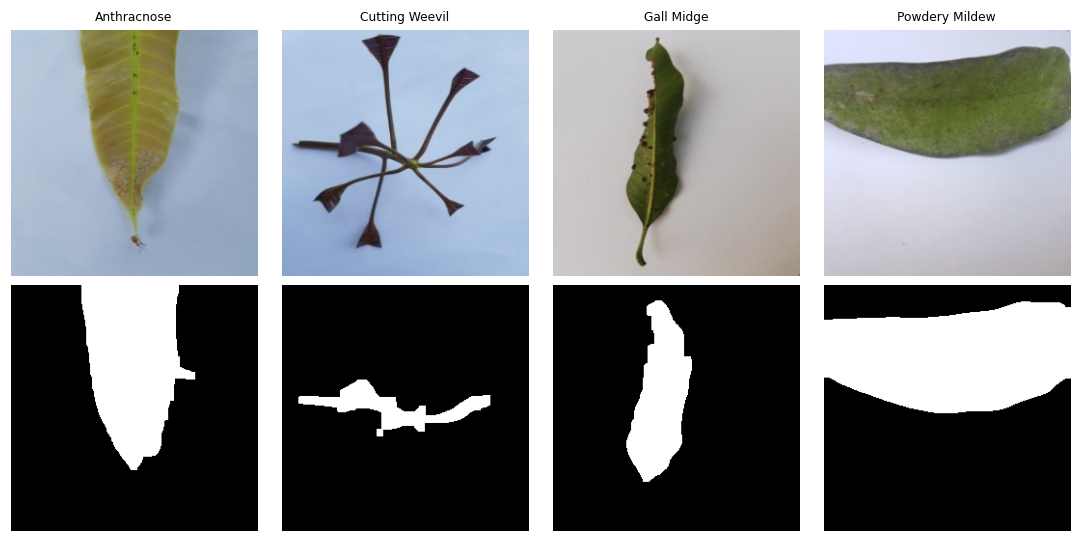

In [ ]:
def leaf_mask(img):
    """Otsu threshold (leaf vs background), cleaned up, largest blob kept."""
    _, mask = cv2.threshold(to_gray(img), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((11, 11), np.uint8))   # fill small holes
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))      # remove specks

    n, labels, st, _ = cv2.connectedComponentsWithStats(mask)
    if n > 1:
        mask = (labels == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)

    # if the mask covers less than 5% or more than 95%, fall back to the full image
    frac = mask.sum() / mask.size
    if frac < 0.05 or frac > 0.95:
        mask = np.ones(mask.shape, np.uint8)
    return mask.astype(bool)


def lesion_proxy(img, leaf):
    """Dark pixels within the leaf area as a rough lesion proxy."""
    dark = ((to_gray(img) < 80) & leaf).astype(np.uint8)
    return cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)).astype(bool)


LEAF = np.stack([leaf_mask(img) for img in IMGS])
LESION = np.stack([lesion_proxy(img, leaf) for img, leaf in zip(IMGS, LEAF)])
df["lesion_of_leaf"] = LESION.sum((1, 2)) / np.maximum(LEAF.sum((1, 2)), 1)

# show examples
fig, axs = plt.subplots(2, 4, figsize=(10, 5))
for k in range(4):
    idx = k * len(IMGS) // 4
    show(axs[0, k], IMGS[idx], CLASSES[Y[idx]], fontsize=8)
    show(axs[1, k], LEAF[idx], cmap="gray")
plt.tight_layout()
plt.show()

### 1.2 Background colour check

Photos of one disease were often taken on the same surface. If background colour differs by class, the model can use it as a shortcut. §10 turns this picture into numbers.

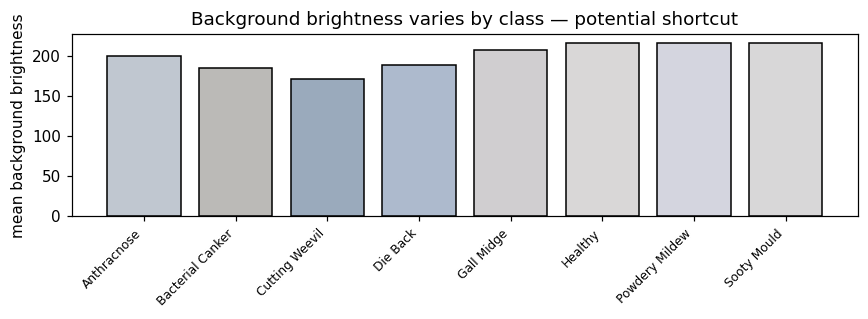

In [ ]:
# average background colour per class (pixels outside leaf mask)
bg_colors = np.array([IMGS[i][~LEAF[i]].mean(axis=0) if (~LEAF[i]).any() else [128, 128, 128]
                      for i in range(len(IMGS))])
means = [bg_colors[Y == c].mean(0) for c in range(NC)]

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(NC), [m.mean() for m in means],
       color=[(m / 255).clip(0, 1) for m in means], edgecolor="black")
ax.set_xticks(range(NC))
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("mean background brightness")
ax.set_title("Background brightness varies by class — potential shortcut")
plt.tight_layout()
plt.show()

### 1.3 Model utilities
Defined early because §2 uses ImageNet features to find near-duplicate photos.

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prep(batch_u8):
    x = torch.from_numpy(np.ascontiguousarray(batch_u8)).permute(0, 3, 1, 2).float() / 255.0
    return (x - MEAN) / STD


def make_model():
    # MANGO_NO_PRETRAINED=1 is only for offline smoke tests; never set it for real runs
    w = None if os.environ.get("MANGO_NO_PRETRAINED") == "1" else models.ResNet50_Weights.IMAGENET1K_V1
    m = models.resnet50(weights=w)
    m.fc = nn.Linear(2048, NC)
    return m


@torch.no_grad()
def predict(model, imgs, bs=64, return_feats=False):
    """Logits for uint8 images (and, optionally, the 2048-d features before the last layer)."""
    model.eval()
    logits_all, feats_all = [], []
    for i in range(0, len(imgs), bs):
        x = prep(imgs[i:i + bs]).to(DEVICE)
        x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        x = model.layer4(model.layer3(model.layer2(model.layer1(x))))
        feat = torch.flatten(model.avgpool(x), 1)
        logits_all.append(model.fc(feat).cpu().numpy())
        feats_all.append(feat.cpu().numpy())
    L = np.concatenate(logits_all)
    return (L, np.concatenate(feats_all)) if return_feats else L


def softmax(L, T=1.0):
    z = L / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def l2n(Fm):
    return Fm / (np.linalg.norm(Fm, axis=1, keepdims=True) + 1e-8)

---
## 2. Leakage-aware split *(feedback: copies across a random split)*

**v1 problem.** Grouping by filename timestamp produced **3,671 groups from 4,000 images**. If there are really ~1,800 distinct leaves, the timestamp key merged only ~330 copies, and most zoom/rotation copies still crossed train/test. That is consistent with v1's 99.8–100% test accuracy.

**v2 fix.**
1. Embed every photo with an **ImageNet** ResNet-50 (not fine-tuned on our data, so the split doesn't depend on the model being evaluated). Average the embedding over 4 rotations × 2 flips so a rotated copy lands near its original.
2. Within each class, cluster with average-linkage on cosine distance. Copies always share a class, so we never merge across classes.
3. Take the **union** with the timestamp groups (connected components).
4. `StratifiedGroupKFold` so no group crosses train/val/test.

**Threshold choice.** We sweep the distance threshold and report group counts. The rule picks the largest threshold (most merging) that still leaves at least 0.9 × the expected number of distinct leaves and no group larger than 40 photos. Using the instructor's number as a prior is a judgement call, so **the montages below must be checked by eye**: merged groups should be the same leaf, and near-misses should be different leaves. Set `DUP_THR` in the config to override.

**Sensitivity (§2.5).** Because the rule leans on that prior, the leakage check is repeated at the thresholds one step below and one step above the chosen one. If the conclusion (a random split inflates accuracy) holds at all three, it does not depend on the exact threshold.

In [ ]:
# ----- 2.1 How many copies does the timestamp key catch? -----
TS_GROUPS = pd.factorize(df["stem_key"])[0]
n_expected = int(round(EXPECTED_DISTINCT * len(df) / 4000))
print(f"Timestamp key: {len(np.unique(TS_GROUPS))} groups from {len(df)} images "
      f"(expected ~{n_expected} distinct leaves)")


# ----- 2.2 Rotation/flip-invariant ImageNet embeddings -----
def invariant_embeddings(imgs, bs=64):
    m = make_model().to(DEVICE).eval()     # ImageNet backbone; fc is unused
    out = []
    for i in range(0, len(imgs), bs):
        b = imgs[i:i + bs]
        views = [np.rot90(b, k, axes=(1, 2)) for k in range(4)]
        views += [v[:, :, ::-1] for v in views]
        feats = [l2n(predict(m, np.ascontiguousarray(v), return_feats=True)[1]) for v in views]
        out.append(sum(feats) / len(views))
    return l2n(np.concatenate(out))


t0 = time.time()
if os.environ.get("MANGO_NO_PRETRAINED") == "1":   # smoke test only: random weights give useless embeddings
    EMB = l2n(np.stack([cv2.resize(im, (16, 16)).ravel() for im in IMGS]).astype(np.float32) - 128)
else:
    EMB = invariant_embeddings(IMGS)
print(f"Embeddings {EMB.shape} in {time.time() - t0:.0f}s")


def dup_groups(E, y, thr):
    """Cluster within each class; returns a global group label per image."""
    lab = np.empty(len(y), int)
    off = 0
    for c in np.unique(y):
        ids = np.where(y == c)[0]
        if len(ids) == 1:
            sub_lab = np.zeros(1, int)
        else:
            sub_lab = AgglomerativeClustering(n_clusters=None, metric="cosine", linkage="average",
                                              distance_threshold=thr).fit(E[ids]).labels_
        lab[ids] = sub_lab + off
        off += sub_lab.max() + 1
    return lab


def union_groups(*labelings):
    """Two images share a group if ANY labeling puts them together (connected components)."""
    n = len(labelings[0])
    rows, cols = [], []
    for lab in labelings:
        o = np.argsort(lab, kind="stable")
        same = lab[o][1:] == lab[o][:-1]
        rows += list(o[:-1][same])
        cols += list(o[1:][same])
    g = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    return connected_components(g, directed=False)[1]


def groups_at(thr):
    return union_groups(dup_groups(EMB, Y, thr), TS_GROUPS)


sweep = []
for thr in [0.005, 0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15]:
    sizes = np.bincount(groups_at(thr))
    sweep.append(dict(threshold=thr, groups=len(sizes), largest_group=sizes.max(),
                      images_in_multi_groups=int(sizes[sizes > 1].sum())))
sweep_df = pd.DataFrame(sweep)
print(sweep_df.to_string(index=False))

MAX_GROUP = 40   # no physical leaf was photographed 40+ times; bigger groups mean chaining
if DUP_THR is not None:
    DUP_THR_USED = float(DUP_THR)
else:
    # most merging that keeps (a) at least ~0.9x the expected number of leaves and (b) no giant group
    ok = sweep_df[(sweep_df.groups >= 0.9 * n_expected) & (sweep_df.largest_group <= MAX_GROUP)]
    DUP_THR_USED = float(ok.threshold.iloc[-1] if len(ok) else sweep_df.threshold.iloc[0])
    if not len(ok):
        print("WARNING: no threshold meets the rule -- inspect the sweep and set DUP_THR by hand.")
GROUPS = groups_at(DUP_THR_USED)
gsz = np.bincount(GROUPS)
print(f"\nUsing threshold {DUP_THR_USED}: {len(gsz)} groups, largest has {gsz.max()} images")
if gsz.max() > MAX_GROUP:
    print("WARNING: a very large group -- check that average linkage is not chaining different leaves.")
sweep_df.to_csv(OUT / "tables" / "dup_threshold_sweep.csv", index=False)

Timestamp key: 3671 groups from 4000 images (expected ~1800 distinct leaves)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 219MB/s]


Embeddings (4000, 2048) in 105s
 threshold  groups  largest_group  images_in_multi_groups
     0.005    3646              5                     615
     0.010    3488              8                     899
     0.020    2680             10                    2126
     0.030    1850             28                    3044
     0.050     889            126                    3722
     0.070     421            323                    3919
     0.100     144            550                    3985
     0.150      29            844                    3996

Using threshold 0.03: 1850 groups, largest has 28 images


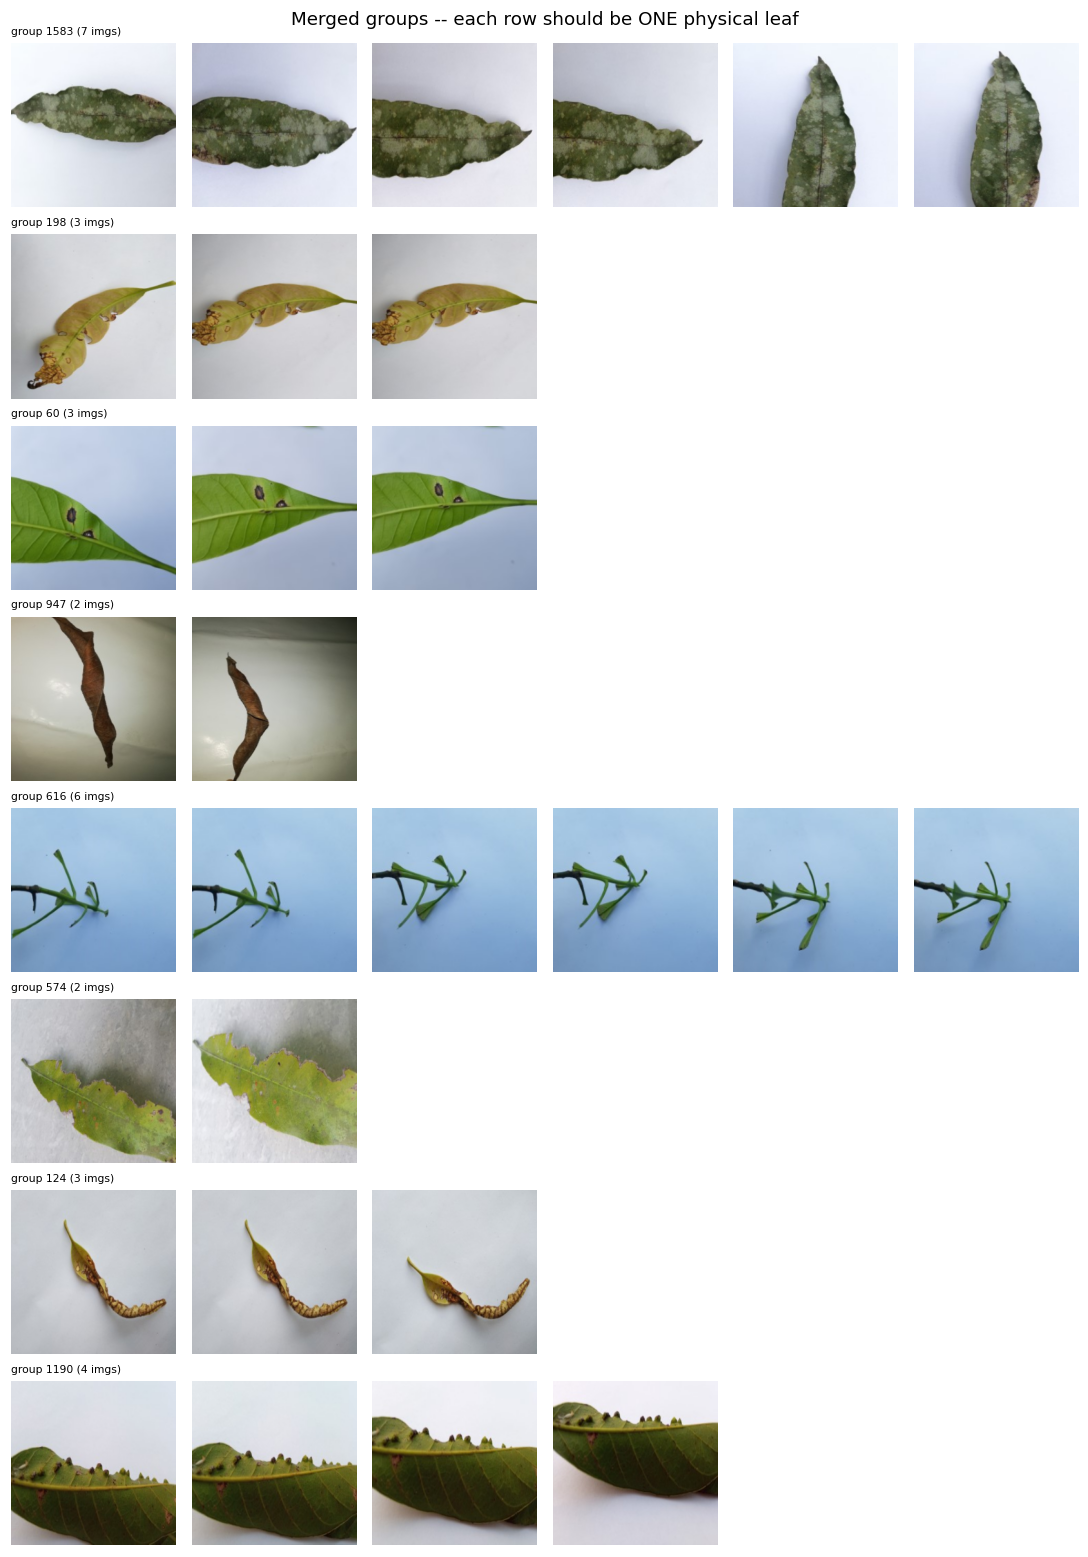

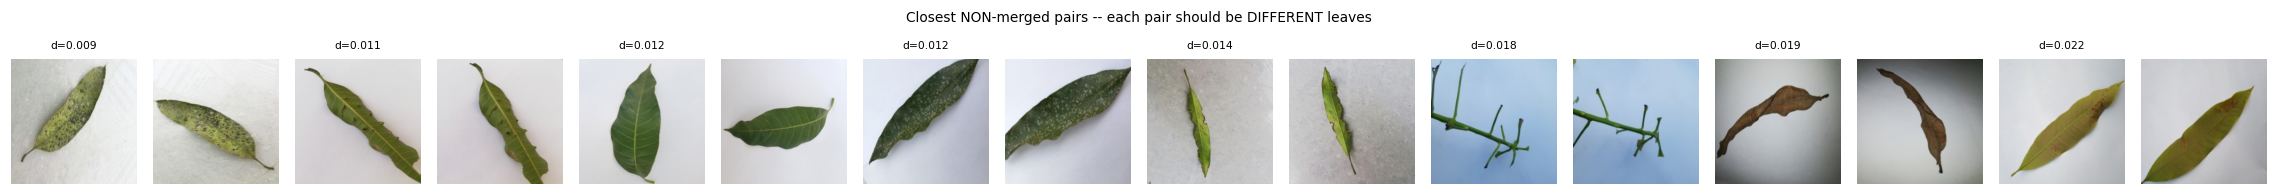

In [ ]:
# ----- 2.3 Visual check: merged groups and near-misses -----
rng = np.random.default_rng(0)
multi = [g for g in np.unique(GROUPS) if gsz[g] > 1]
show_g = rng.choice(multi, min(8, len(multi)), replace=False) if multi else []
fig, axs = plt.subplots(max(len(show_g), 1), 6, figsize=(10, 1.8 * max(len(show_g), 1)), squeeze=False)
for r, g in enumerate(show_g):
    mem = np.where(GROUPS == g)[0][:6]
    for k in range(6):
        show(axs[r, k], IMGS[mem[k]] if k < len(mem) else None)
    axs[r, 0].set_title(f"group {g} ({gsz[g]} imgs)", fontsize=7, loc="left")
plt.suptitle("Merged groups -- each row should be ONE physical leaf")
savefig("dup_groups")

# nearest pairs that were NOT merged (should be different leaves)
near = []
for c in range(NC):
    ids = np.where(Y == c)[0]
    D = 1 - EMB[ids] @ EMB[ids].T
    np.fill_diagonal(D, 9)
    D[GROUPS[ids][:, None] == GROUPS[ids][None, :]] = 9     # ignore pairs already in one group
    a, b = np.unravel_index(D.argmin(), D.shape)
    if D[a, b] < 9:
        near.append((ids[a], ids[b], D[a, b]))
near = sorted(near, key=lambda t: t[2])   # one pair per class
if near:
    fig, axs = plt.subplots(1, 2 * len(near), figsize=(2 * len(near) * 1.3, 1.8))
    for k, (a, b, d) in enumerate(near):
        show(axs[2 * k], IMGS[a], f"d={d:.3f}")
        show(axs[2 * k + 1], IMGS[b])
    plt.suptitle("Closest NON-merged pairs -- each pair should be DIFFERENT leaves", fontsize=9)
    savefig("dup_near_misses")

In [ ]:
# ----- 2.4 Split, and how much the old split leaked -----
def make_split(y, groups, seed):
    """~71% train / 14% val / 14% test, stratified, groups never split."""
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    folds = [te for _, te in sgkf.split(np.zeros(len(y)), y, groups)]
    return np.concatenate(folds[2:]), folds[1], folds[0]


# leak audit of the v1 split (timestamp groups only)
o_tr, o_va, o_te = make_split(Y, TS_GROUPS, SPLIT_SEED)
leak_rate_old = np.isin(GROUPS[o_te], GROUPS[o_tr]).mean()
print(f"v1 split: {leak_rate_old:.1%} of test images have a near-duplicate in train")

idx_tr, idx_va, idx_te = make_split(Y, GROUPS, SPLIT_SEED)
for a, b in itertools.combinations([idx_tr, idx_va, idx_te], 2):
    assert not np.isin(GROUPS[a], GROUPS[b]).any(), "group leaked!"
SPLIT_TAG = hashlib.md5(np.sort(idx_tr).tobytes()).hexdigest()[:8]
print(f"v2 split: train {len(idx_tr)}, val {len(idx_va)}, test {len(idx_te)} | split tag {SPLIT_TAG}")

# how much does ignoring groups inflate accuracy? (same model, same test size, 3 repeats each)
X_small = np.stack([cv2.resize(im, (64, 64)).ravel() for im in IMGS]).astype(np.float32) / 255.0


def pix_lr_acc(tr, te):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
    clf.fit(X_small[tr], Y[tr])
    return accuracy_score(Y[te], clf.predict(X_small[te]))


def grouped_acc(groups):
    """Pixel-LR test accuracy on 3 grouped splits."""
    accs = []
    for s in [42, 43, 44]:
        tr, _, te = make_split(Y, groups, s)
        accs.append(pix_lr_acc(tr, te))
    return accs


naive = [pix_lr_acc(tr, te) for tr, te in
         StratifiedShuffleSplit(n_splits=3, test_size=0.14, random_state=42).split(X_small, Y)]
grouped = grouped_acc(GROUPS)
leak_df = pd.DataFrame({"split": ["random (ignores copies)", "grouped (v2)"],
                        "pixel-LR acc mean": [np.mean(naive), np.mean(grouped)],
                        "sd": [np.std(naive), np.std(grouped)]})
print(leak_df.round(3).to_string(index=False))
LEAK_INFLATION = 100 * (np.mean(naive) - np.mean(grouped))
print(f"=> a random split inflates accuracy by ~{LEAK_INFLATION:.1f} pp (3 repeats each, n is small)")
print(pd.crosstab(df.iloc[idx_te]["cls"], columns="test count").to_string())

# ----- 2.5 Does this conclusion depend on the grouping threshold? -----
# The threshold was chosen with the instructor's ~1,800 as a prior, so repeat the check one step either side.
thrs = sweep_df.threshold.tolist()
j = thrs.index(DUP_THR_USED) if DUP_THR_USED in thrs else None
rows = []
for thr in ([DUP_THR_USED] if j is None else thrs[max(j - 1, 0):j + 2]):
    g = GROUPS if thr == DUP_THR_USED else groups_at(thr)
    accs = grouped if thr == DUP_THR_USED else grouped_acc(g)
    rows.append({"threshold": thr, "groups": len(np.unique(g)), "pixel-LR acc mean": np.mean(accs), "sd": np.std(accs),
                 "inflation of random split (pp)": 100 * (np.mean(naive) - np.mean(accs)),
                 "used": thr == DUP_THR_USED})
SPLIT_SENS = pd.DataFrame(rows)
del X_small
print("\nSensitivity to the grouping threshold (same pixel-LR check):")
print(SPLIT_SENS.round(3).to_string(index=False))

v1 split: 63.6% of test images have a near-duplicate in train
v2 split: train 2831, val 586, test 583 | split tag 8aef8619
                  split  pixel-LR acc mean    sd
random (ignores copies)              0.801 0.012
           grouped (v2)              0.738 0.022
=> a random split inflates accuracy by ~6.3 pp (3 repeats each, n is small)
col_0             test count
cls                         
Anthracnose               74
Bacterial Canker          73
Cutting Weevil            62
Die Back                  64
Gall Midge                59
Healthy                   97
Powdery Mildew            56
Sooty Mould               98

Sensitivity to the grouping threshold (same pixel-LR check):
 threshold  groups  pixel-LR acc mean    sd  inflation of random split (pp)  used
      0.02    2680              0.754 0.011                           4.680 False
      0.03    1850              0.738 0.022                           6.296  True
      0.05     889              0.701 0.019             

---
## 3. Interpretable baseline *(feedback: "inherently interpretable" depends on the features)*

Logistic regression on **27 named features** a person can read:
- **Shape (4):** leaf area fraction, aspect ratio, solidity, outline complexity
- **Colour means & spreads inside leaf (11):** L/a/b mean+std (CIELAB), H mean, S mean+std, V mean+std (HSV)
- **Colour fractions inside leaf (5):** green, yellow, brown, dark, whitish. These are partly collinear (they roughly sum to 1), so some coefficients may be unstable; the sign-stability check flags which.
- **Lesion proxy geometry (4):** lesion area fraction, log count, log mean size, largest blob fraction
- **Texture (3):** Laplacian log-variance, gradient magnitude, edge density

Coefficients are standardised so they can be compared. Regularisation is chosen on validation macro-F1. Sign stability is checked with a **group** bootstrap (whole leaves are resampled, not single photos).

In [ ]:
FEATURE_NAMES = [
    "leaf_area_frac", "leaf_aspect", "leaf_solidity", "leaf_outline_complexity",
    "L_mean", "L_std", "a_mean", "a_std", "b_mean", "b_std",
    "H_mean", "S_mean", "S_std", "V_mean", "V_std",
    "frac_green", "frac_yellow", "frac_brown", "frac_dark", "frac_whitish",
    "lesion_area_of_leaf", "lesion_count_log", "lesion_mean_size_log",
    "lesion_largest_of_leaf",
    "texture_laplacian_logvar", "texture_gradient_mean", "texture_edge_density",
]


def extract_features(img, leaf, lesion):
    """Extract 27 named, human-readable features from one image."""
    f = dict.fromkeys(FEATURE_NAMES, 0.0)
    n = max(int(leaf.sum()), 1)
    if n >= 800:   # otherwise too little leaf was detected: all features stay 0
        # --- shape ---
        cnts, _ = cv2.findContours(leaf.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea)
        area = cv2.contourArea(c) + 1e-6
        rw, rh = cv2.minAreaRect(c)[1]
        f["leaf_area_frac"] = n / leaf.size
        f["leaf_aspect"] = min(max(rw, rh) / (min(rw, rh) + 1e-6), 20.0)
        f["leaf_solidity"] = area / (cv2.contourArea(cv2.convexHull(c)) + 1e-6)
        f["leaf_outline_complexity"] = min(cv2.arcLength(c, True) ** 2 / (4 * np.pi * area), 50.0)

        # --- colour: CIELAB and HSV (inside leaf only) ---
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
        for ch, k in enumerate(["L", "a", "b"]):
            v = lab[:, :, ch][leaf]
            f[f"{k}_mean"], f[f"{k}_std"] = v.mean(), v.std()
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
        H, S, V = (hsv[:, :, ch][leaf] for ch in range(3))
        f["H_mean"] = H.mean()
        f["S_mean"], f["S_std"] = S.mean(), S.std()
        f["V_mean"], f["V_std"] = V.mean(), V.std()

        # --- colour fractions (partly collinear) ---
        f["frac_green"]   = np.mean((H >= 35) & (H <= 85) & (S >= 50))
        f["frac_yellow"]  = np.mean((H >= 20) & (H < 35) & (S >= 60))
        f["frac_brown"]   = np.mean((H < 20) & (S >= 50))
        f["frac_dark"]    = np.mean(V < 70)
        f["frac_whitish"] = np.mean((S < 40) & (V >= 140))

        # --- lesion proxy geometry ---
        nl, _, st, _ = cv2.connectedComponentsWithStats(lesion.astype(np.uint8), connectivity=8)
        sizes = st[1:, cv2.CC_STAT_AREA] if nl > 1 else np.array([0])
        f["lesion_area_of_leaf"] = lesion.sum() / n
        f["lesion_count_log"] = np.log1p(nl - 1)
        f["lesion_mean_size_log"] = np.log1p(sizes.mean())
        f["lesion_largest_of_leaf"] = sizes.max() / n

        # --- texture (inside eroded leaf core to avoid edge artefacts) ---
        gray = to_gray(img)
        core = cv2.erode(leaf.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
        if core.sum() > 100:
            gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
            gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
            f["texture_laplacian_logvar"] = np.log1p(cv2.Laplacian(gray, cv2.CV_32F)[core].var())
            f["texture_gradient_mean"] = np.sqrt(gx ** 2 + gy ** 2)[core].mean()
            f["texture_edge_density"] = (cv2.Canny(gray, 50, 150) > 0)[core].mean()
    return np.array([f[k] for k in FEATURE_NAMES], np.float32)


def make_lr(C, penalty):
    return make_pipeline(StandardScaler(), LogisticRegression(
        C=C, penalty=penalty, solver="lbfgs" if penalty == "l2" else "saga",
        max_iter=4000, class_weight="balanced"))


def coef_matrix(pipe):
    """Coefficients as a [class, feature] array (rows stay 0 for classes missing from the fit)."""
    coef = np.zeros((NC, len(FEATURE_NAMES)))
    coef[pipe[-1].classes_] = pipe[-1].coef_
    return coef


X_HC = np.stack([extract_features(IMGS[i], LEAF[i], LESION[i]) for i in range(len(IMGS))])
print(f"Feature matrix: {X_HC.shape} -- {len(FEATURE_NAMES)} features")

# regularisation search on the validation set
best_f1, best_C, best_pen = 0, 1.0, "l2"
for pen in ["l2", "l1"]:
    for C in [0.03, 0.1, 0.3, 1, 3]:
        m = make_lr(C, pen).fit(X_HC[idx_tr], Y[idx_tr])
        f1 = f1_score(Y[idx_va], m.predict(X_HC[idx_va]), average="macro")
        if f1 > best_f1:
            best_f1, best_C, best_pen = f1, C, pen
print(f"Best: penalty={best_pen}, C={best_C}, val macro-F1={best_f1:.3f}")

LR_HC = make_lr(best_C, best_pen).fit(X_HC[idx_tr], Y[idx_tr])
P_lr = LR_HC.predict_proba(X_HC)
acc_lr = accuracy_score(Y[idx_te], P_lr[idx_te].argmax(1))
f1_lr = f1_score(Y[idx_te], P_lr[idx_te].argmax(1), average="macro")
print(f"Interpretable LR -- test acc {acc_lr:.3f} | macro-F1 {f1_lr:.3f}")

Feature matrix: (4000, 27) -- 27 features
Best: penalty=l1, C=3, val macro-F1=0.952
Interpretable LR -- test acc 0.937 | macro-F1 0.936


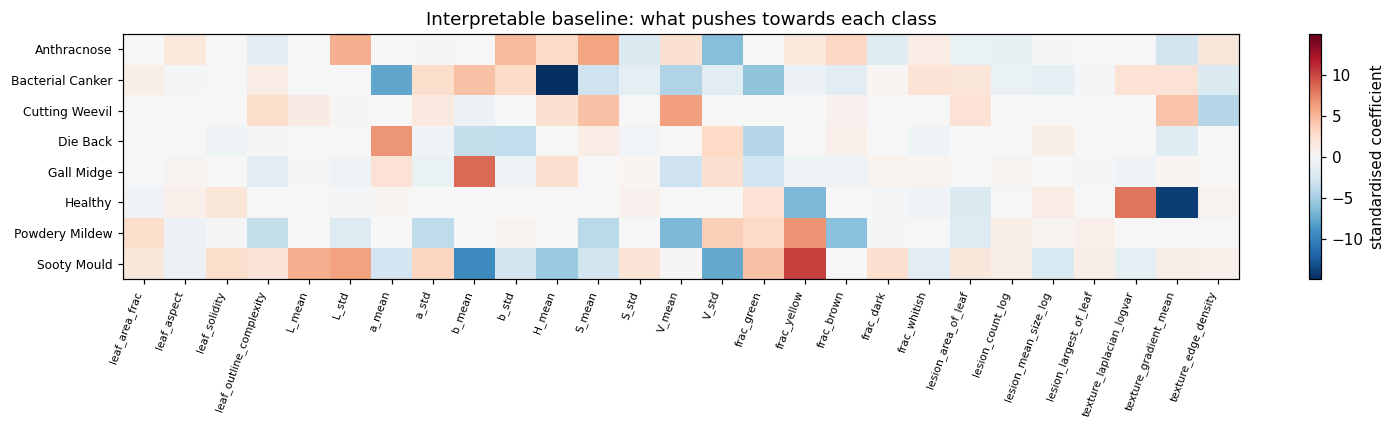

Anthracnose      -- V_std (-6.32), S_mean (+5.94), L_std (+5.36), b_std (+4.75)
Bacterial Canker -- H_mean (-14.92), a_mean (-7.70), frac_green (-6.05), V_mean (-4.53)
Cutting Weevil   -- V_mean (+6.17), S_mean (+4.40), texture_edge_density (-4.31), texture_gradient_mean (+4.27)
Die Back         -- a_mean (+6.65), frac_green (-4.28), b_std (-3.62), b_mean (-3.56)
Gall Midge       -- b_mean (+8.48), V_mean (-3.10), frac_green (-2.85), V_std (+2.55)
Healthy          -- texture_gradient_mean (-14.01), texture_laplacian_logvar (+8.00), frac_yellow (-6.74), frac_green (+2.16)
Powdery Mildew   -- frac_yellow (+6.73), V_mean (-6.71), frac_brown (-6.19), S_mean (-4.08)
Sooty Mould      -- frac_yellow (+10.24), b_mean (-9.46), V_std (-7.65), L_std (+5.97)

Sign stability of top-quartile coefficients: median 1.00
Share with stability >= 0.9: 100%
Large-but-unstable coefficients (interpret with care): []


In [ ]:
# ----- Can a person read the coefficients? -----
coef = coef_matrix(LR_HC)
coef_df = pd.DataFrame(coef, index=CLASSES, columns=FEATURE_NAMES)


def top_features(c, k):
    return coef_df.loc[c].abs().sort_values(ascending=False).head(k).index


fig, ax = plt.subplots(figsize=(14, 4))
vmax = np.abs(coef).max()
im = ax.imshow(coef, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(NC))
ax.set_yticklabels(CLASSES, fontsize=8)
plt.colorbar(im, label="standardised coefficient")
plt.title("Interpretable baseline: what pushes towards each class")
plt.tight_layout()
plt.show()

for c in CLASSES:
    print(f"{c:16s} -- " + ", ".join(f"{k} ({coef_df.loc[c, k]:+.2f})" for k in top_features(c, 4)))

# sign stability under a GROUP bootstrap (whole leaves are resampled, not single photos)
rng = np.random.default_rng(0)
ug = np.unique(GROUPS[idx_tr])
signs = []
for _ in range(50):
    gs = rng.choice(ug, len(ug), replace=True)
    ids = np.concatenate([idx_tr[GROUPS[idx_tr] == g] for g in gs])
    signs.append(np.sign(coef_matrix(make_lr(best_C, best_pen).fit(X_HC[ids], Y[ids]))))

stab = np.abs(np.mean(signs, 0))
top_mask = np.abs(coef) >= np.percentile(np.abs(coef), 75)
print(f"\nSign stability of top-quartile coefficients: median {np.median(stab[top_mask]):.2f}")
print(f"Share with stability >= 0.9: {(stab[top_mask] >= 0.9).mean():.0%}")

unstable = [(CLASSES[i], FEATURE_NAMES[j]) for i, j in zip(*np.where(top_mask & (stab < 0.7)))]
print(f"Large-but-unstable coefficients (interpret with care): {unstable[:12]}")

# flag coefficients that encode photo framing rather than symptoms
FRAMING = ["leaf_area_frac"]
flag = [(c, feat) for c in CLASSES for feat in top_features(c, 4) if feat in FRAMING]
if flag:
    print(f"Top-4 coefficients encoding photo framing rather than symptoms: {flag}")

---
## 4. ResNet-50: fine-tuning and classification

ImageNet-pretrained ResNet-50, fine-tuned with a lower backbone learning rate. Three seeds are used for stability (§9).
Checkpoint names include a hash of the training indices, so **checkpoints from the v1 split are never reused**.

In [ ]:
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.25, 0.2, 0.15),
])


class TrainDS(Dataset):
    def __init__(self, idx, override=None):
        self.idx = idx
        self.override = override or {}   # {global index: (replacement image, replacement label)} (used in §8.4)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img, label = self.override.get(j, (IMGS[j], Y[j]))
        x = train_tf(torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1))
        return (x.float() / 255 - MEAN[0]) / STD[0], int(label)


def train_resnet(seed, tag="main", epochs=EPOCHS, override=None):
    """Fine-tune one ResNet-50 (or load its checkpoint); keeps the epoch with the best validation macro-F1."""
    ck = OUT / "ckpt" / f"resnet50_{tag}_seed{seed}_{SPLIT_TAG}.pt"
    model = make_model().to(DEVICE)
    if REUSE_CKPT and ck.exists():
        model.load_state_dict(torch.load(ck, map_location=DEVICE))
        print(f"{tag} seed {seed}: loaded {ck.name}")
        return model.eval()

    set_seed(seed)
    dl = DataLoader(TrainDS(idx_tr, override), batch_size=BATCH, shuffle=True,
                    drop_last=len(idx_tr) > BATCH, generator=torch.Generator().manual_seed(seed))
    head = list(model.fc.parameters())
    body = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
    opt = torch.optim.AdamW([{"params": body, "lr": LR_BACK},
                             {"params": head, "lr": LR_HEAD}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR_BACK, LR_HEAD],
                                                total_steps=epochs * len(dl), pct_start=0.15)
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    best_f1, best_sd = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for x, y in dl:
            loss = crit(model(x.to(DEVICE)), y.to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
        f1 = f1_score(Y[idx_va], predict(model, IMGS[idx_va]).argmax(1), average="macro")
        print(f"  {tag} seed {seed} ep {ep + 1}/{epochs} val-F1 {f1:.3f} ({time.time() - t0:.0f}s)")
        if f1 > best_f1:
            best_f1, best_sd = f1, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_sd)
    torch.save(best_sd, ck)
    return model.eval()


MODELS = {s: train_resnet(s) for s in SEEDS}
model = MODELS[SEEDS[0]]
n_params = sum(p.numel() for p in model.parameters())
print(f"ResNet-50: {n_params / 1e6:.1f}M parameters, 50 layers, "
      f"{sum(1 for m in model.modules() if isinstance(m, nn.Conv2d))} conv layers")

  main seed 0 ep 1/12 val-F1 0.995 (23s)
  main seed 0 ep 2/12 val-F1 0.993 (22s)
  main seed 0 ep 3/12 val-F1 1.000 (22s)
  main seed 0 ep 4/12 val-F1 0.995 (22s)
  main seed 0 ep 5/12 val-F1 1.000 (22s)
  main seed 0 ep 6/12 val-F1 0.998 (22s)
  main seed 0 ep 7/12 val-F1 1.000 (22s)
  main seed 0 ep 8/12 val-F1 0.998 (22s)
  main seed 0 ep 9/12 val-F1 1.000 (22s)
  main seed 0 ep 10/12 val-F1 1.000 (22s)
  main seed 0 ep 11/12 val-F1 1.000 (22s)
  main seed 0 ep 12/12 val-F1 1.000 (22s)
  main seed 1 ep 1/12 val-F1 0.996 (22s)
  main seed 1 ep 2/12 val-F1 0.995 (22s)
  main seed 1 ep 3/12 val-F1 1.000 (22s)
  main seed 1 ep 4/12 val-F1 1.000 (22s)
  main seed 1 ep 5/12 val-F1 1.000 (22s)
  main seed 1 ep 6/12 val-F1 1.000 (22s)
  main seed 1 ep 7/12 val-F1 1.000 (22s)
  main seed 1 ep 8/12 val-F1 1.000 (22s)
  main seed 1 ep 9/12 val-F1 1.000 (22s)
  main seed 1 ep 10/12 val-F1 1.000 (22s)
  main seed 1 ep 11/12 val-F1 1.000 (22s)
  main seed 1 ep 12/12 val-F1 1.000 (22s)
  main see

                         model  test_acc  test_macroF1
Interpretable LR (27 features)    0.9365        0.9356
              ResNet-50 seed 0    1.0000        1.0000
              ResNet-50 seed 1    1.0000        1.0000
              ResNet-50 seed 2    1.0000        1.0000

ResNet-50 (mean of seeds) is 6.3 points above the interpretable baseline.
The justification for the complex model has to come from the triage metrics (§5) and robustness (§10),
not from accuracy alone -- see the verdict table in §17.

Per-class (seed 0):
                  precision  recall   F1  support
Anthracnose             1.0     1.0  1.0       74
Bacterial Canker        1.0     1.0  1.0       73
Cutting Weevil          1.0     1.0  1.0       62
Die Back                1.0     1.0  1.0       64
Gall Midge              1.0     1.0  1.0       59
Healthy                 1.0     1.0  1.0       97
Powdery Mildew          1.0     1.0  1.0       56
Sooty Mould             1.0     1.0  1.0       98


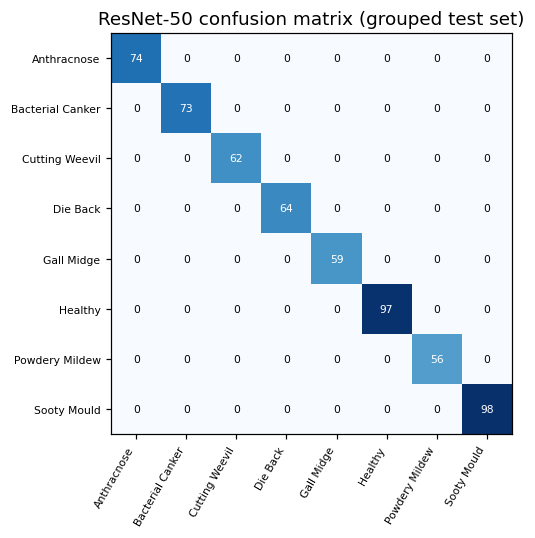

In [ ]:
# ----- Predictions and model vs baseline (confidence calibration is in §11) -----
LOGITS, FEATS = {}, {}
for s, mdl in MODELS.items():
    LOGITS[s], FEATS[s] = predict(mdl, IMGS, return_feats=True)
L0, F0 = LOGITS[SEEDS[0]], FEATS[SEEDS[0]]


def mf1(y, p):
    return f1_score(y, p, average="macro", labels=range(NC))


def plot_cm(cm, labels, title, cmap, figsize, small=False):
    """Confusion matrix with counts; small=True uses the compact style for the 8-class matrix."""
    fs = 7 if small else None
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(cm, cmap=cmap)
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=fs, **({"rotation": 60, "ha": "right"} if small else {}))
    ax.set_yticklabels(labels, fontsize=fs)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=fs,
                    color="w" if small and cm[i, j] > cm.max() / 2 else "k")
    ax.set_title(title)
    return ax


yt = Y[idx_te]
rows = [("Interpretable LR (27 features)", P_lr[idx_te].argmax(1))]
rows += [(f"ResNet-50 seed {s}", LOGITS[s][idx_te].argmax(1)) for s in SEEDS]
cmp_df = pd.DataFrame([(name, accuracy_score(yt, p), mf1(yt, p)) for name, p in rows],
                      columns=["model", "test_acc", "test_macroF1"])
print(cmp_df.round(4).to_string(index=False))
RES_ACC = cmp_df.test_acc.iloc[1:].mean()
GAP_PTS = 100 * (RES_ACC - cmp_df.test_acc.iloc[0])
print(f"\nResNet-50 (mean of seeds) is {GAP_PTS:.1f} points above the interpretable baseline.")
print("The justification for the complex model has to come from the triage metrics (§5) and robustness (§10),"
      "\nnot from accuracy alone -- see the verdict table in §17.")

pr0 = L0[idx_te].argmax(1)
p, r, f, sup = precision_recall_fscore_support(yt, pr0, labels=range(NC), zero_division=0)
print("\nPer-class (seed 0):")
print(pd.DataFrame({"precision": p, "recall": r, "F1": f, "support": sup}, index=CLASSES).round(3).to_string())

plot_cm(confusion_matrix(yt, pr0, labels=range(NC)), CLASSES,
        "ResNet-50 confusion matrix (grouped test set)", "Blues", (6, 5), small=True)
savefig("confusion")

---
## 5. Triage-aware evaluation *(feedback: which mistakes hurt the officer most?)*

Missing a High-priority disease is worse than confusing two Low-priority ones, so we also evaluate at the **tier** level. If the clean test set has no errors, every number here is zero and says nothing; the informative tier numbers are then the ones under field conditions (§10.3), and that is the row used in the verdict table.

**Tier table — sources.** Each tier needs a citation the officer would recognise (e.g. a national extension service or a plant-pathology review). **TODO (team): fill in the Source column before submission. Do not cite fruit-damage literature for a leaf-image tier** (v1 feedback on Cutting Weevil).

| Class | Tier | Why (leaf-level) | Source |
|---|---|---|---|
| Anthracnose | High | spreads fast in wet weather; also infects fruit | TODO |
| Bacterial Canker | High | spreads by rain splash and tools | TODO |
| Die Back | High | can kill branches or the whole tree | TODO |
| Powdery Mildew | High | flowering-stage losses | TODO |
| Gall Midge | Moderate | | TODO |
| Sooty Mould | Low | superficial; reduces photosynthesis | TODO |
| Cutting Weevil | Low | leaf damage mainly on new flushes | TODO |
| Healthy | None | | — |

missed_high  0.000
false_alarm  0.000
cross_tier   0.000
accuracy     1.000


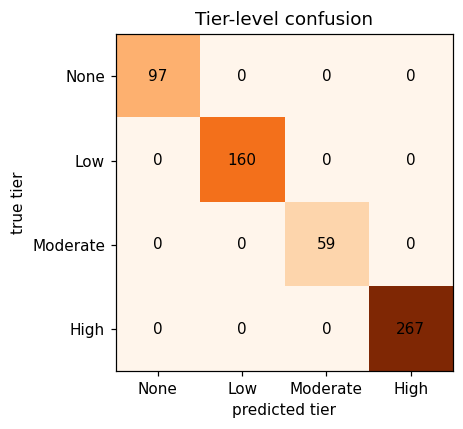


Total errors: 0
NOTE: no errors on the clean test set, so the tier metrics above cannot tell anything apart.
The informative tier numbers are the ones under field conditions (§10.3).


In [ ]:
TRIAGE = {
    "Anthracnose": "High", "Bacterial Canker": "High",
    "Die Back": "High", "Powdery Mildew": "High",
    "Gall Midge": "Moderate",
    "Sooty Mould": "Low", "Cutting Weevil": "Low",
    "Healthy": "None",
}
TIER_NAMES = ["None", "Low", "Moderate", "High"]


def tier_vec(table=TRIAGE):
    """Tier number (0 = None ... 3 = High) of every class, in CLASSES order."""
    return np.array([TIER_NAMES.index(table[c]) for c in CLASSES])


tv = tier_vec()


def tier_metrics(pred, y, table=TRIAGE):
    t = tier_vec(table)
    tt, tp = t[y], t[pred]
    hi = tt == 3
    return {"missed_high": (tp[hi] < 3).mean() if hi.any() else np.nan,
            "false_alarm": ((tp == 3) & (tt < 3)).mean(),
            "cross_tier": (tt != tp).mean(),
            "accuracy": (pred == y).mean()}


pred = L0[idx_te].argmax(1)
for k, v in tier_metrics(pred, yt).items():
    print(f"{k:12s} {v:.3f}")

ax = plot_cm(confusion_matrix(tv[yt], tv[pred], labels=range(4)), TIER_NAMES,
             "Tier-level confusion", "Oranges", (4.5, 4))
ax.set_xlabel("predicted tier"); ax.set_ylabel("true tier")
savefig("tier_confusion")

err = pd.DataFrame({"true": np.array(CLASSES)[yt], "pred": np.array(CLASSES)[pred]})
err = err[err.true != err.pred]
print(f"\nTotal errors: {len(err)}")
if len(err):
    print(err.value_counts().head(8).to_string())
else:
    print("NOTE: no errors on the clean test set, so the tier metrics above cannot tell anything apart.\n"
          "The informative tier numbers are the ones under field conditions (§10.3).")

### 5.1 Sensitivity to the tier table
The tier table is expert judgement, so we check whether the triage conclusions survive plausible alternatives.
§10 repeats this under simulated field conditions, where there are enough errors for the table to matter.

In [ ]:
ALT_TABLES = {
    "baseline": TRIAGE,
    "Gall Midge -> High": {**TRIAGE, "Gall Midge": "High"},
    "Powdery Mildew -> Moderate": {**TRIAGE, "Powdery Mildew": "Moderate"},
    "Sooty Mould & Cutting Weevil -> Moderate": {**TRIAGE, "Sooty Mould": "Moderate", "Cutting Weevil": "Moderate"},
}


def tier_sensitivity(pred, y):
    return pd.DataFrame({k: tier_metrics(pred, y, t) for k, t in ALT_TABLES.items()}).T


sens_clean = tier_sensitivity(pred, yt)
print("Clean test set:")
print(sens_clean.round(3).to_string())

Clean test set:
                                          missed_high  false_alarm  cross_tier  accuracy
baseline                                          0.0          0.0         0.0       1.0
Gall Midge -> High                                0.0          0.0         0.0       1.0
Powdery Mildew -> Moderate                        0.0          0.0         0.0       1.0
Sooty Mould & Cutting Weevil -> Moderate          0.0          0.0         0.0       1.0


---
## 6. Grad-CAM explanations

Grad-CAM on the last bottleneck block (`layer4[-1]`) via the `pytorch-grad-cam` library.
Every metric below is also computed for **null explainers** that know nothing about the model:
- **random:** smooth random blobs
- **center:** a Gaussian at the image centre
- **edge:** blurred Sobel edge magnitude of the image
- **leaf:** the blurred leaf mask

If Grad-CAM cannot beat these, its scores reflect image structure, not the model.

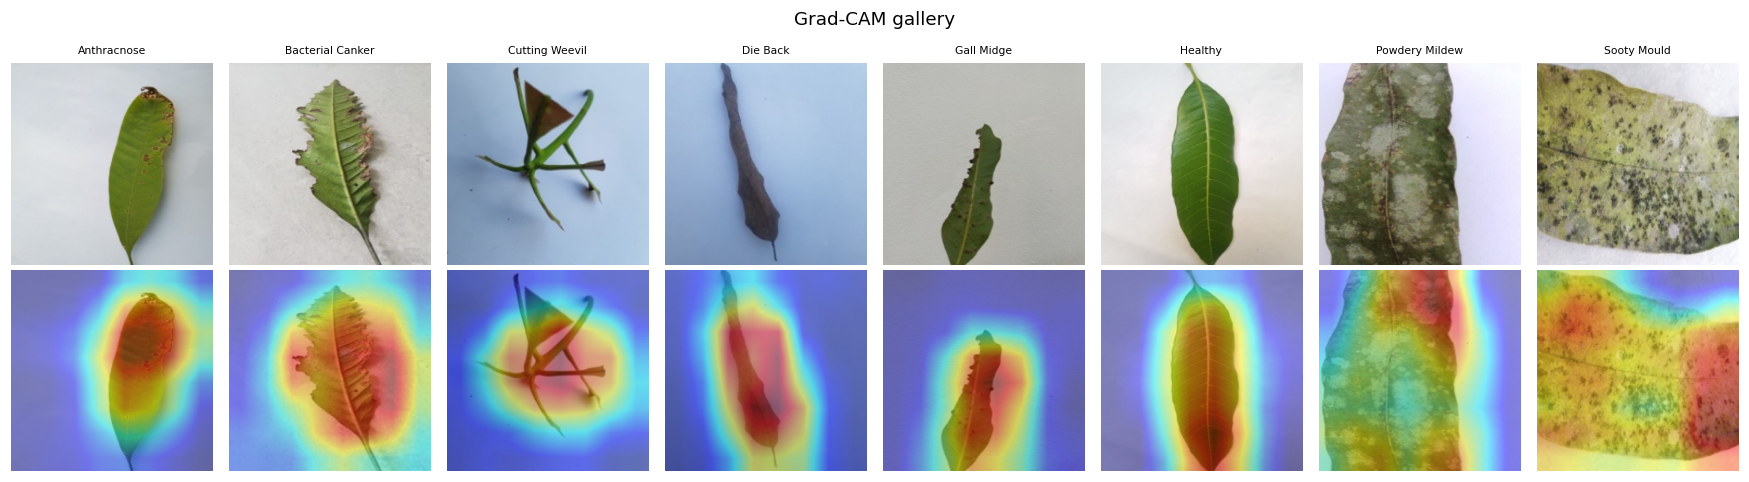

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def get_gradcam_maps(model, imgs, targets=None, bs=32):
    """Grad-CAM heat maps in [0, 1]; explains the predicted class unless `targets` is given."""
    if targets is None:
        targets = predict(model, imgs, bs=bs).argmax(1)
    with GradCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
        return np.stack([
            cam(input_tensor=prep(imgs[j:j + 1]).to(DEVICE), targets=[ClassifierOutputTarget(int(t))])[0]
            for j, t in enumerate(targets)])


# ----- null explainers (they know nothing about the model) -----
yy, xx = np.mgrid[:IMG, :IMG]
CENTER_MAP = np.exp(
    -(((yy - IMG / 2) / (0.28 * IMG)) ** 2
      + ((xx - IMG / 2) / (0.28 * IMG)) ** 2) / 2
).astype(np.float32)
CENTER_MAP = (CENTER_MAP - CENTER_MAP.min()) / (CENTER_MAP.max() - CENTER_MAP.min())


def null_random(rng):
    return norm01(cv2.resize(rng.random((8, 8)).astype(np.float32), (IMG, IMG), interpolation=cv2.INTER_CUBIC))


def null_edge(img):
    g = to_gray(img).astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return norm01(cv2.GaussianBlur(m, (0, 0), 6))


def null_leaf(leaf):
    return norm01(cv2.GaussianBlur(leaf.astype(np.float32), (0, 0), 6))


def null_maps(imgs, leafs=None, seed=0):
    """All null explainers for a set of images: {name: maps}. 'leaf' needs the leaf masks."""
    rng = np.random.default_rng(seed)
    maps = {"random": np.stack([null_random(rng) for _ in imgs]),
            "center": np.stack([CENTER_MAP] * len(imgs)),
            "edge": np.stack([null_edge(im) for im in imgs])}
    if leafs is not None:
        maps["leaf"] = np.stack([null_leaf(lf) for lf in leafs])
    return maps


# ----- shared map measurements -----
def mass_share(cam, mask):
    """Share of the heat-map mass that falls inside `mask`."""
    return cam[mask].sum() / (cam.sum() + 1e-8)


def points_at(cam, mask):
    """Pointing game: is the hottest pixel inside `mask` (with a 9 px tolerance)?"""
    return dilate(mask, 9)[np.unravel_index(cam.argmax(), cam.shape)]


def overlay(img, cam, alpha=0.45):
    h = cv2.applyColorMap((255 * cam).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return (img * (1 - alpha) + h * alpha).astype(np.uint8)


# ----- gallery: one correctly classified test image per class -----
rng = np.random.default_rng(3)
show_idx = []
for c in range(NC):
    ok = [i for i in idx_te if Y[i] == c and L0[i].argmax() == c]
    if ok:
        show_idx.append(rng.choice(ok))
show_idx = np.array(show_idx, dtype=int)
if len(show_idx) == 0:   # e.g. untrained smoke-test model
    show_idx = idx_te[:min(4, len(idx_te))]
show_cams = get_gradcam_maps(model, IMGS[show_idx])

fig, axs = plt.subplots(2, len(show_idx), figsize=(2 * len(show_idx), 4.5), squeeze=False)
for k, i in enumerate(show_idx):
    show(axs[0, k], IMGS[i], CLASSES[Y[i]])
    show(axs[1, k], overlay(IMGS[i], show_cams[k]))
plt.suptitle("Grad-CAM gallery")
plt.tight_layout()
plt.show()

---
## 7. Plausibility: do heat maps land on lesions?

Plausibility means "the explanation *looks* right". It is necessary but not sufficient; §8 tests whether the model *uses* those regions.

Metrics (dark-spot classes only, where the lesion proxy means something):
- **Lesion enrichment:** CAM mass on lesions ÷ the mass expected if the CAM were uniform over the leaf. >1 means concentrated on lesions.
- **Pointing game:** the CAM maximum falls inside a (9 px-dilated) lesion.
- **Off-leaf mass:** share of CAM mass outside the leaf, i.e. on the background.

v2 adds **paired** comparisons: on the *same* image, how often does Grad-CAM beat each null?

Localisation set: 233 images
          enrichment  pointing_hit  off_leaf_mass
Grad-CAM       1.144         0.399          0.534
random         0.991         0.052          0.716
center         1.067         0.352          0.604
edge           1.396         0.601          0.395
leaf           1.002         0.305          0.086

Paired, per image:
        enrichment: GC > null  pointing: GC hit & null miss  pointing: null hit & GC miss
random                  0.584                         0.361                         0.013
center                  0.618                         0.215                         0.167
edge                    0.343                         0.142                         0.343
leaf                    0.549                         0.258                         0.163

Nulls that match or beat Grad-CAM on lesion plausibility: ['edge']


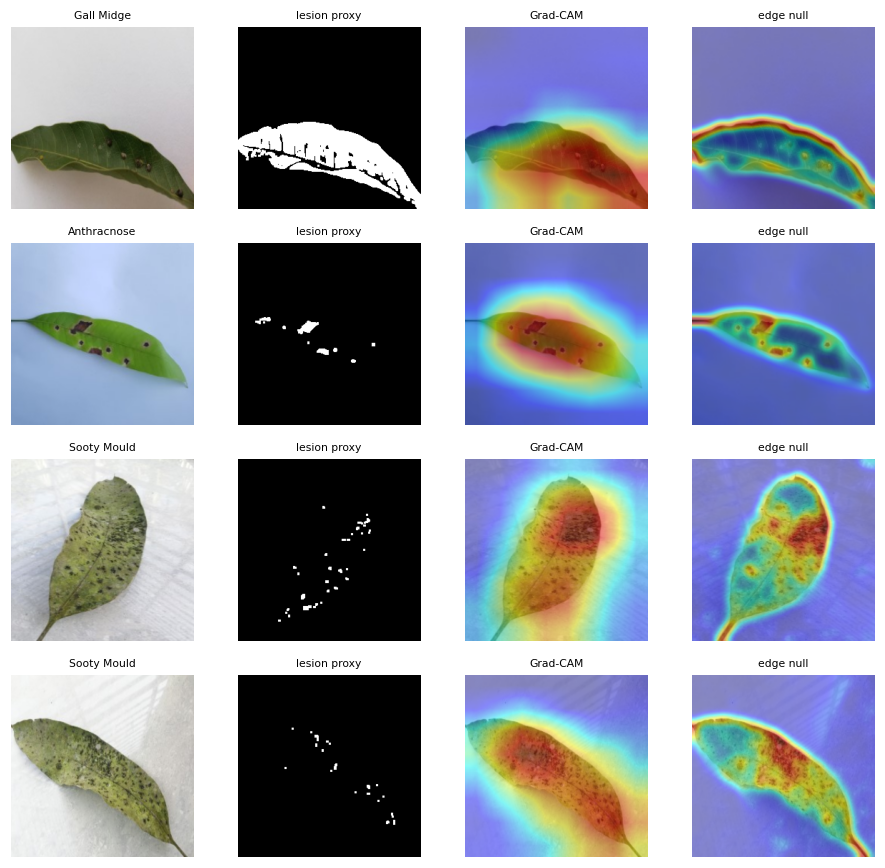

In [ ]:
LOC_CLASSES = [c for c in ["Anthracnose", "Bacterial Canker", "Gall Midge", "Sooty Mould"] if c in CLASSES]


def loc_metrics(cam, leaf, target):
    lesion_share = cam[target & leaf].sum() / (cam[leaf].sum() + 1e-8)      # of the on-leaf mass
    area_share = (target & leaf).sum() / (leaf.sum() + 1e-8)
    return dict(enrichment=lesion_share / (area_share + 1e-8),
                pointing_hit=float(points_at(cam, target)),
                off_leaf_mass=mass_share(cam, ~leaf))


loc_idx = np.array([i for i in idx_te
                    if CLASSES[Y[i]] in LOC_CLASSES and L0[i].argmax() == Y[i]
                    and 0.01 <= df.lesion_of_leaf.iloc[i] <= 0.6])
print(f"Localisation set: {len(loc_idx)} images")

PLAUS = None
if len(loc_idx) >= 3:
    cams_loc = get_gradcam_maps(model, IMGS[loc_idx])
    methods = {"Grad-CAM": cams_loc, **null_maps(IMGS[loc_idx], LEAF[loc_idx])}
    per_img = {name: pd.DataFrame([loc_metrics(M[k], LEAF[i], LESION[i]) for k, i in enumerate(loc_idx)])
               for name, M in methods.items()}
    PLAUS = pd.DataFrame({n: d.mean() for n, d in per_img.items()}).T
    print(PLAUS.round(3).to_string())

    # paired: share of images where Grad-CAM is strictly better than each null
    gc = per_img.pop("Grad-CAM")
    PLAUS_PAIRED = pd.DataFrame({n: {
        "enrichment: GC > null": (gc.enrichment > d.enrichment).mean(),
        "pointing: GC hit & null miss": ((gc.pointing_hit == 1) & (d.pointing_hit == 0)).mean(),
        "pointing: null hit & GC miss": ((gc.pointing_hit == 0) & (d.pointing_hit == 1)).mean(),
    } for n, d in per_img.items()}).T
    print("\nPaired, per image:")
    print(PLAUS_PAIRED.round(3).to_string())
    beaten_by = [n for n in per_img
                 if PLAUS.loc[n, "enrichment"] >= PLAUS.loc["Grad-CAM", "enrichment"]
                 or PLAUS.loc[n, "pointing_hit"] >= PLAUS.loc["Grad-CAM", "pointing_hit"]]
    print(f"\nNulls that match or beat Grad-CAM on lesion plausibility: {beaten_by or 'none'}")

    pick = np.random.default_rng(5).choice(len(loc_idx), min(4, len(loc_idx)), replace=False)
    fig, axs = plt.subplots(len(pick), 4, figsize=(8.5, 2 * len(pick)), squeeze=False)
    for r, k in enumerate(pick):
        i = loc_idx[k]
        show(axs[r, 0], IMGS[i], CLASSES[Y[i]])
        show(axs[r, 1], LESION[i], "lesion proxy", cmap="gray")
        show(axs[r, 2], overlay(IMGS[i], cams_loc[k]), "Grad-CAM")
        show(axs[r, 3], overlay(IMGS[i], methods["edge"][k]), "edge null")
    savefig("plausibility_panel")

### 7.2 Lesion annotation kit *(feedback: no lesion locations to compare against)*
The cell exports 40 test images (10 per dark-spot class). **Team task:** in any paint program, make a same-size black PNG and paint lesions white, then save it as `annotation_kit/masks/<same name>.png`.
When masks are present, re-running this cell reports how well the dark-pixel proxy matches human annotation, and the pointing game for Grad-CAM vs the edge null against **human** masks.

In [ ]:
kit = OUT / "annotation_kit"
(kit / "images").mkdir(parents=True, exist_ok=True)
(kit / "masks").mkdir(parents=True, exist_ok=True)
rng_k = np.random.default_rng(11)
kit_idx = []
for c in LOC_CLASSES:
    pool = [i for i in idx_te if CLASSES[Y[i]] == c]
    kit_idx += list(rng_k.choice(pool, min(10, len(pool)), replace=False))
for i in kit_idx:
    cv2.imwrite(str(kit / "images" / f"kit_{i:05d}.png"), cv2.cvtColor(IMGS[i], cv2.COLOR_RGB2BGR))
print(f"{len(kit_idx)} images in {kit / 'images'}")

ann = []
for i in kit_idx:
    mp = kit / "masks" / f"kit_{i:05d}.png"
    if mp.exists():
        human = cv2.resize(cv2.imread(str(mp), 0), (IMG, IMG), interpolation=cv2.INTER_NEAREST) > 127
        both = (LESION[i] & human).sum()
        ann.append({
            "proxy_precision": both / max(LESION[i].sum(), 1),
            "proxy_recall": both / max(human.sum(), 1),
            "proxy_IoU": both / max((LESION[i] | human).sum(), 1),
            "GradCAM_pointing": float(points_at(get_gradcam_maps(model, IMGS[i][None])[0], human)),
            "edge_pointing": float(points_at(null_edge(IMGS[i]), human)),
        })
ANN = pd.DataFrame(ann) if ann else None
if ANN is not None:
    print(f"Human-annotated masks found for {len(ANN)} images")
    print(ANN.mean().round(3).to_string())
else:
    print("No masks yet -- the proxy is unvalidated. Say so in the report if this stays empty.")

40 images in /content/drive/MyDrive/XDS/mango_outputs_v2/annotation_kit/images
No masks yet -- the proxy is unvalidated. Say so in the report if this stays empty.


---
## 8. Faithfulness: does the model actually *use* the highlighted region?

### 8.1 Deletion / insertion curves (Petsiuk et al., 2018)
Rank pixels by saliency, then progressively replace them with a baseline (deletion) or reveal them on top of the baseline (insertion).
A faithful map makes the predicted-class probability **drop fast** on deletion (low AUC) and **rise fast** on insertion (high AUC).

**v2 changes**
- **Two baselines** (heavy blur and flat grey), because the "removed" pixels are themselves an input the model reacts to.
- **Bias check:** what does the model predict on a *fully* blurred or greyed image? If it is always one class, the deletion curve is biased towards images of that class.
- **Paired statistics:** per-image AUC difference between Grad-CAM and each null, with 95% bootstrap CIs over images and the share of images where Grad-CAM wins.
- Probabilities use T = 1 (raw softmax), so the temperature in §11 cannot change the result.

In [ ]:
STEPS = np.linspace(0, 1, 11 if QUICK_MODE else 21)
_trapz = getattr(np, "trapezoid", None) or np.trapz


def auc(curves):
    """Area under each curve (one row per image)."""
    return _trapz(curves, STEPS, axis=1)


def make_base(img, kind):
    if kind == "blur":
        return cv2.GaussianBlur(img, (0, 0), 14)
    return np.full_like(img, (124, 116, 104))   # ImageNet mean colour


def del_ins_curves(model, img, cam, cls, kind):
    """p(cls) while the most salient pixels are progressively removed (deletion) or revealed (insertion)."""
    order_ = np.argsort(-cam, axis=None)
    rank = np.empty_like(order_)
    rank[order_] = np.arange(order_.size)
    rank = rank.reshape(cam.shape)
    base = make_base(img, kind)
    masks = [(rank < frac * rank.size)[..., None] for frac in STEPS]
    batch = [np.where(m, base, img) for m in masks] + [np.where(m, img, base) for m in masks]
    probs = softmax(predict(model, np.stack(batch), bs=32))[:, cls]
    return probs[:len(STEPS)], probs[len(STEPS):]


faith_idx = np.array([i for i in idx_te if L0[i].argmax() == Y[i]], dtype=int)
if len(faith_idx) < 3:   # only happens with an untrained smoke-test model
    faith_idx = np.array(idx_te)
faith_idx = np.random.default_rng(7).choice(faith_idx, min(N_FAITH, len(faith_idx)), replace=False)
cls_f = L0[faith_idx].argmax(1)

# --- bias check: what does a fully removed image look like to the model? ---
for kind in ["blur", "grey"]:
    full = np.stack([make_base(IMGS[i], kind) for i in faith_idx])
    pc = Counter(str(CLASSES[k]) for k in predict(model, full).argmax(1))
    top, n_top = pc.most_common(1)[0]
    print(f"Fully {'blurred' if kind == 'blur' else 'greyed'} images -> predicted classes: {dict(pc)}")
    if n_top / len(faith_idx) > 0.5:
        print(f"  BIAS: {n_top / len(faith_idx):.0%} become '{top}'. Deletion curves for '{top}' images are "
              f"flattered/penalised by this baseline.")

cams_faith = get_gradcam_maps(model, IMGS[faith_idx])
all_maps = {"Grad-CAM": cams_faith, **null_maps(IMGS[faith_idx], LEAF[faith_idx])}

DEL, INS, FA = {}, {}, {}     # DEL[baseline][method] = curves, one row per image
for kind in ["blur", "grey"]:
    DEL[kind], INS[kind] = {}, {}
    for m, M in all_maps.items():
        curves = [del_ins_curves(model, IMGS[i], M[k], cls_f[k], kind) for k, i in enumerate(faith_idx)]
        DEL[kind][m] = np.array([d for d, _ in curves])
        INS[kind][m] = np.array([n for _, n in curves])
    FA[kind] = pd.DataFrame({m: {"deletion_AUC": auc(DEL[kind][m]).mean(),
                                 "insertion_AUC": auc(INS[kind][m]).mean()} for m in all_maps}).T
    FA[kind]["ins_minus_del"] = FA[kind].insertion_AUC - FA[kind].deletion_AUC
    print(f"\n[{kind} baseline] mean AUCs over {len(faith_idx)} images")
    print(FA[kind].round(3).to_string())

Fully blurred images -> predicted classes: {'Cutting Weevil': 39, 'Anthracnose': 14, 'Die Back': 17, 'Gall Midge': 99, 'Healthy': 31}
Fully greyed images -> predicted classes: {'Gall Midge': 200}
  BIAS: 100% become 'Gall Midge'. Deletion curves for 'Gall Midge' images are flattered/penalised by this baseline.

[blur baseline] mean AUCs over 200 images
          deletion_AUC  insertion_AUC  ins_minus_del
Grad-CAM         0.443          0.854          0.411
random           0.692          0.688         -0.004
center           0.554          0.836          0.282
edge             0.420          0.789          0.368
leaf             0.442          0.822          0.380

[grey baseline] mean AUCs over 200 images
          deletion_AUC  insertion_AUC  ins_minus_del
Grad-CAM         0.379          0.826          0.447
random           0.509          0.503         -0.006
center           0.489          0.792          0.302
edge             0.344          0.673          0.329
leaf             0.

baseline    metric   null  GC advantage  CI low  CI high  GC win rate             verdict
    blur  deletion random         0.249   0.232    0.265        0.980           GC better
    blur  deletion center         0.110   0.099    0.122        0.940           GC better
    blur  deletion   edge        -0.023  -0.033   -0.014        0.370         null better
    blur  deletion   leaf        -0.001  -0.013    0.011        0.370 no clear difference
    blur insertion random         0.166   0.150    0.180        0.985           GC better
    blur insertion center         0.018   0.012    0.025        0.710           GC better
    blur insertion   edge         0.065   0.056    0.076        0.795           GC better
    blur insertion   leaf         0.032   0.024    0.041        0.720           GC better
    grey  deletion random         0.130   0.109    0.149        0.785           GC better
    grey  deletion center         0.110   0.100    0.121        0.910           GC better
    grey  

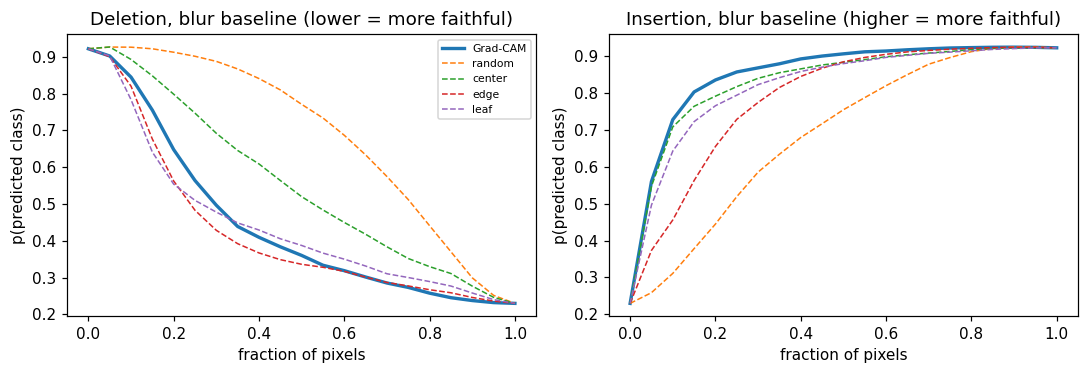

In [ ]:
# ----- paired comparison: is Grad-CAM better than each null ON THE SAME IMAGE? -----
def paired_summary(gc, null, lower_is_better, n_boot=2000, seed=0):
    d = (null - gc) if lower_is_better else (gc - null)     # positive = Grad-CAM better
    rng = np.random.default_rng(seed)
    boots = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
    return {"GC advantage": d.mean(), "CI low": np.percentile(boots, 2.5),
            "CI high": np.percentile(boots, 97.5), "GC win rate": (d > 0).mean()}


NULLS = [m for m in all_maps if m != "Grad-CAM"]
PAIRED = pd.DataFrame([
    {"baseline": kind, "metric": metric, "null": m,
     **paired_summary(auc(store[kind]["Grad-CAM"]), auc(store[kind][m]), lower)}
    for kind in ["blur", "grey"]
    for metric, store, lower in [("deletion", DEL, True), ("insertion", INS, False)]
    for m in NULLS])
PAIRED["verdict"] = np.where(PAIRED["CI low"] > 0, "GC better",
                     np.where(PAIRED["CI high"] < 0, "null better", "no clear difference"))
print(PAIRED.round(3).to_string(index=False))

not_beaten = PAIRED[PAIRED.verdict != "GC better"]
if len(not_beaten):
    print("\nGrad-CAM is NOT reliably more faithful than:")
    for _, r in not_beaten.iterrows():
        print(f"  - {r['null']:6s} on {r['metric']} ({r['baseline']} baseline): "
              f"advantage {r['GC advantage']:+.3f} [{r['CI low']:+.3f}, {r['CI high']:+.3f}]")
else:
    print("\nGrad-CAM beats every null on both metrics and both baselines (CIs exclude 0).")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for m in all_maps:
    lw, ls = (2.2, "-") if m == "Grad-CAM" else (1, "--")
    ax[0].plot(STEPS, DEL["blur"][m].mean(0), label=m, lw=lw, ls=ls)
    ax[1].plot(STEPS, INS["blur"][m].mean(0), label=m, lw=lw, ls=ls)
ax[0].set_title("Deletion, blur baseline (lower = more faithful)")
ax[1].set_title("Insertion, blur baseline (higher = more faithful)")
for a in ax:
    a.set_xlabel("fraction of pixels"); a.set_ylabel("p(predicted class)")
ax[0].legend(fontsize=7)
savefig("deletion_insertion")

### 8.2 Sanity check: cascading randomisation (Adebayo et al., 2018)

Progressively re-initialise weights from the top layer down. A map that depends on the model must **change**; if it doesn't, it just reflects image structure.
Note that the model-free nulls (edge, leaf) would score 1.0 at every step, so this test separates Grad-CAM from them, unlike §8.1.
Because Grad-CAM uses the gradient of the class logit, randomising `fc` alone should already destroy the class-specific map; a rebound at lower layers means the remaining structure comes from the image.

             state  correlation with original
           trained                      1.000
    + randomise fc                      0.062
+ randomise layer4                      0.092
+ randomise layer3                      0.350
+ randomise layer2                      0.102
+ randomise layer1                      0.393
 + randomise conv1                      0.191


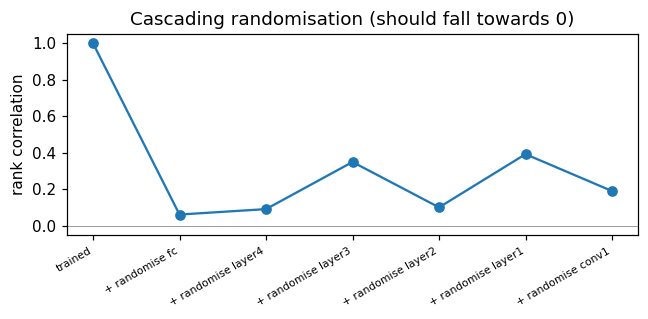

In [ ]:
def small(M, s=32):
    """Downsample maps to 32x32 and flatten for correlation."""
    return np.stack([cv2.resize(m, (s, s), interpolation=cv2.INTER_AREA) for m in M]).reshape(len(M), -1)


def mean_spearman(A, B):
    """Mean rank correlation between paired maps (compared at 32x32)."""
    return np.nanmean([stats.spearmanr(a, b)[0] for a, b in zip(small(A), small(B))])


sub = faith_idx[:min(len(faith_idx), 40)]
tgt = L0[sub].argmax(1)
ref_maps = get_gradcam_maps(model, IMGS[sub], targets=tgt)

# progressively randomise layers, top to bottom
rnd_model = copy.deepcopy(model)
curve = [("trained", 1.0)]
torch.manual_seed(123)
for name in ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]:
    for m in getattr(rnd_model, name).modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    cur_maps = get_gradcam_maps(rnd_model, IMGS[sub], targets=tgt)
    curve.append((f"+ randomise {name}", mean_spearman(ref_maps, cur_maps)))

sc = pd.DataFrame(curve, columns=["state", "correlation with original"])
print(sc.round(3).to_string(index=False))

plt.figure(figsize=(6, 3))
plt.plot(range(len(sc)), sc.iloc[:, 1], "o-")
plt.xticks(range(len(sc)), sc.state, rotation=30, ha="right", fontsize=7)
plt.axhline(0, c="gray", lw=0.5)
plt.ylabel("rank correlation")
plt.title("Cascading randomisation (should fall towards 0)")
plt.tight_layout()
plt.show()

### 8.3 Faithfulness to a shortcut we can measure: the background
§10 shows the model's accuracy drops when the background is replaced. We can measure, **per image**, how much the prediction depends on the background:
`reliance = p(pred | original) − p(pred | grey background)`.
If Grad-CAM is faithful, images where the model leans on the background should get more heat-map mass **off the leaf**.
We report the Spearman correlation between reliance and off-leaf mass (with the edge null as a model-free reference), and the off-leaf enrichment (mass share ÷ area share) for images whose label flips without the background.

In [ ]:
GREY = [128, 128, 128]


def with_background(i, bg_rgb):
    """Image i with everything off the leaf painted one colour."""
    out = IMGS[i].copy()
    out[~dilate(LEAF[i], 5)] = np.uint8(bg_rgb)
    return out


bg_idx = np.array([i for i in idx_te if 0.05 < (~LEAF[i]).mean() < 0.9])   # skip images with no usable mask
Po = softmax(predict(model, IMGS[bg_idx]))
Pg = softmax(predict(model, np.stack([with_background(i, GREY) for i in bg_idx])))
pred_o = Po.argmax(1)
ar = np.arange(len(bg_idx))
reliance = Po[ar, pred_o] - Pg[ar, pred_o]
flipped = pred_o != Pg.argmax(1)

cams_bg = get_gradcam_maps(model, IMGS[bg_idx], targets=pred_o)
off_area = np.array([(~LEAF[i]).mean() for i in bg_idx])
off_gc = np.array([mass_share(cams_bg[k], ~LEAF[i]) for k, i in enumerate(bg_idx)])
off_edge = np.array([mass_share(null_edge(IMGS[i]), ~LEAF[i]) for i in bg_idx])

rho_gc = stats.spearmanr(reliance, off_gc)[0]
rho_edge = stats.spearmanr(reliance, off_edge)[0]


def by_flip(x):
    """Mean of x for the images whose label flips, and for those whose label survives."""
    return [x[flipped].mean() if flipped.any() else np.nan, x[~flipped].mean()]


BGF = pd.DataFrame({"images": [flipped.sum(), (~flipped).sum()], "mean reliance": by_flip(reliance),
                    "GC off-leaf mass": by_flip(off_gc), "off-leaf area": by_flip(off_area)},
                   index=["label flips without background", "label survives"])
BGF["GC off-leaf enrichment"] = BGF["GC off-leaf mass"] / BGF["off-leaf area"]
print(BGF.round(3).to_string())
print(f"\nSpearman(reliance, off-leaf mass): Grad-CAM {rho_gc:.3f} | edge null {rho_edge:.3f}  (n={len(bg_idx)})")
if flipped.any() and BGF.loc["label flips without background", "GC off-leaf enrichment"] < 1:
    print("=> For images that NEED the background, Grad-CAM puts LESS than its area share there: "
          "the heat map hides the shortcut.")

                                images  mean reliance  GC off-leaf mass  off-leaf area  GC off-leaf enrichment
label flips without background      14          0.721             0.702          0.816                   0.861
label survives                     486          0.093             0.511          0.719                   0.711

Spearman(reliance, off-leaf mass): Grad-CAM 0.373 | edge null 0.307  (n=500)
=> For images that NEED the background, Grad-CAM puts LESS than its area share there: the heat map hides the shortcut.


### 8.4 White-box check with a planted shortcut (synthetic data check)

We know the ground truth only if we put it there ourselves (cf. Adebayo et al., 2022).
- Stamp a small magenta square at a random position on `PATCH_FRAC` (10%) of the **diseased** training images and **label them Healthy**, then train a second ResNet-50 (same recipe, seed 0, fewer epochs). These leaves still look diseased, so the square is the only way the model can fit their label. (v2 stamped the square on Healthy leaves; Healthy was already perfectly separable, the model ignored the square, and the check could not run.)
- At test time, stamp the square on **diseased** test leaves. If the prediction flips to Healthy, the model is using the square, and we know exactly where the evidence is.
- A faithful explainer must then point at the square. We report the pointing-game hit rate and mass enrichment on the square for Grad-CAM, the nulls, and Grad-CAM of the **original** model on the same images (a model that doesn't use the square should *not* highlight it).

This is also the most dangerous failure for the officer: a sticker, label or finger in the photo turning a diseased leaf into "Healthy".

Stamped 250 of 2503 diseased training images and labelled them 'Healthy'; patch 25x25 px (1.0% of the image)
  backdoor_Healthy seed 0 ep 1/6 val-F1 0.977 (22s)
  backdoor_Healthy seed 0 ep 2/6 val-F1 0.998 (22s)
  backdoor_Healthy seed 0 ep 3/6 val-F1 0.991 (22s)
  backdoor_Healthy seed 0 ep 4/6 val-F1 1.000 (22s)
  backdoor_Healthy seed 0 ep 5/6 val-F1 1.000 (22s)
  backdoor_Healthy seed 0 ep 6/6 val-F1 1.000 (22s)
Patched model: clean test acc 0.997; diseased leaves + square -> 'Healthy': 100.0%
Original model on the same stamped images -> 'Healthy': 0.0%

Explainers on the 486 images the patched model calls 'Healthy':
                           pointing hit  mass on patch  enrichment
Grad-CAM (patched model)          0.533          0.095       9.982
Grad-CAM (original model)         0.025          0.010       0.999
edge                              0.029          0.023       2.404
center                            0.019          0.011       1.174
random                            0

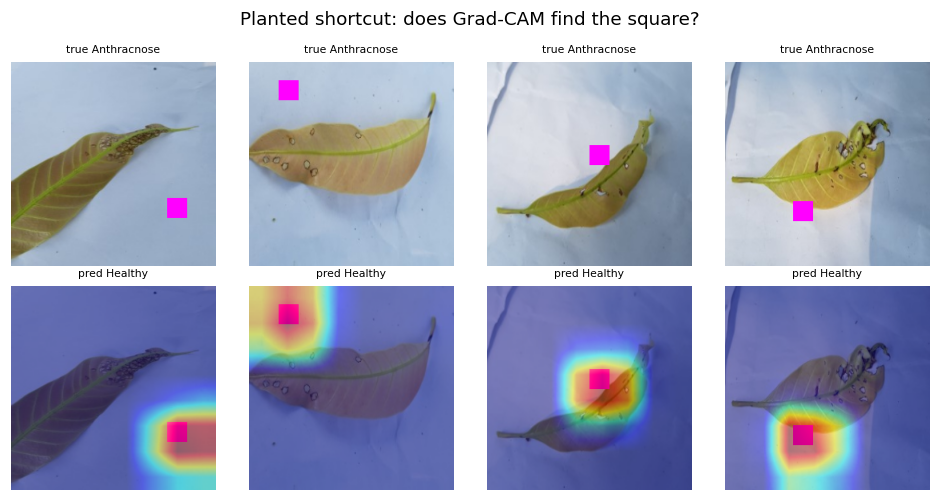

In [ ]:
PATCH = max(8, IMG // 10)
PATCH_RGB = (255, 0, 255)
PC = CLASSES.index(PATCH_CLASS)


def stamp(img, rng):
    """Paste the square at a random position; returns (stamped image, mask of the square)."""
    y0, x0 = rng.integers(0, IMG - PATCH, 2)
    m = np.zeros(img.shape[:2], bool)
    m[y0:y0 + PATCH, x0:x0 + PATCH] = True
    out = img.copy()
    out[m] = PATCH_RGB
    return out, m


# Stamp the square on some DISEASED training leaves and label them PATCH_CLASS. These leaves still look
# diseased, so the square is the only way the model can fit their label: it has to learn the shortcut.
rng_p = np.random.default_rng(13)
tr_dis = [i for i in idx_tr if Y[i] != PC]
poisoned = rng_p.choice(tr_dis, int(PATCH_FRAC * len(tr_dis)), replace=False)
OVERRIDE = {int(i): (stamp(IMGS[i], rng_p)[0], PC) for i in poisoned}
print(f"Stamped {len(OVERRIDE)} of {len(tr_dis)} diseased training images and labelled them '{PATCH_CLASS}'; "
      f"patch {PATCH}x{PATCH} px ({PATCH ** 2 / IMG ** 2:.1%} of the image)")

model_p = train_resnet(0, tag=f"backdoor_{PATCH_CLASS.replace(' ', '')}", epochs=PATCH_EPOCHS, override=OVERRIDE)
acc_p_clean = (predict(model_p, IMGS[idx_te]).argmax(1) == yt).mean()

# stamp the square on DISEASED test leaves: does the prediction flip to PATCH_CLASS?
rng_t = np.random.default_rng(17)
te_dis = np.array([i for i in idx_te if Y[i] != PC])
stamped = [stamp(IMGS[i], rng_t) for i in te_dis]
T_IMGS = np.stack([s[0] for s in stamped]); T_MASK = np.stack([s[1] for s in stamped])
pred_tp = predict(model_p, T_IMGS).argmax(1)
SHORTCUT_RATE = (pred_tp == PC).mean()
base_rate = (predict(model, T_IMGS).argmax(1) == PC).mean()
print(f"Patched model: clean test acc {acc_p_clean:.3f}; diseased leaves + square -> '{PATCH_CLASS}': {SHORTCUT_RATE:.1%}")
print(f"Original model on the same stamped images -> '{PATCH_CLASS}': {base_rate:.1%}")

sel = np.where(pred_tp == PC)[0]
PATCH_TAB = None
if len(sel) < 5:
    print("Too few flips for a meaningful explainer test -- increase PATCH_FRAC / PATCH_EPOCHS and report this.")
else:
    imgs_s, masks_s = T_IMGS[sel], T_MASK[sel]
    nulls = null_maps(imgs_s)
    maps = {
        "Grad-CAM (patched model)": get_gradcam_maps(model_p, imgs_s, targets=np.full(len(sel), PC)),
        "Grad-CAM (original model)": get_gradcam_maps(model, imgs_s),
        **{n: nulls[n] for n in ["edge", "center", "random"]},
    }
    area = PATCH ** 2 / IMG ** 2
    rows = {}
    for n, M in maps.items():
        mass = np.mean([mass_share(cam, m) for cam, m in zip(M, masks_s)])
        rows[n] = {"pointing hit": np.mean([points_at(cam, m) for cam, m in zip(M, masks_s)]),
                   "mass on patch": mass, "enrichment": mass / area}
    PATCH_TAB = pd.DataFrame(rows).T
    print(f"\nExplainers on the {len(sel)} images the patched model calls '{PATCH_CLASS}':")
    print(PATCH_TAB.round(3).to_string())
    print("\nRead: 'Grad-CAM (patched)' should be far above 'Grad-CAM (original)'. The edge null also likes a "
          "high-contrast square,\nso Grad-CAM gets credit only for what it finds beyond the edge null.")

    n_show = min(4, len(sel))
    fig, axs = plt.subplots(2, n_show, figsize=(2.2 * n_show, 4.6), squeeze=False)
    for k in range(n_show):
        show(axs[0, k], imgs_s[k], f"true {CLASSES[Y[te_dis[sel[k]]]]}")
        show(axs[1, k], overlay(imgs_s[k], maps["Grad-CAM (patched model)"][k]), f"pred {PATCH_CLASS}")
    plt.suptitle("Planted shortcut: does Grad-CAM find the square?")
    savefig("planted_patch")

---
## 9. Stability *(feedback: same input twice; small input changes)*

**Protocol (what we chose and why)**
- **Repeat runs:** Grad-CAM has no sampling, so two runs on the same input should be identical. We verify this rather than assume it. This is the main practical difference from LIME, which samples perturbations.
- **Across retraining:** `N_STAB` = 60 correctly classified test images (enough to show the spread while keeping all seed pairs cheap), 3 seeds → 3 pairs.
- **Small input changes:** Gaussian noise (σ = 8), +10% brightness, an 8 px shift, JPEG q = 60. These are chosen so that the label almost never changes; images whose label does change are excluded from the map comparison and counted separately.
- **Agreement measures:** Spearman rank correlation on 32 × 32 downsampled maps, and IoU of the top-20% pixels.
- **Control:** the same measure between maps of *different* images (shuffled pairs). Because every map tends to cover the leaf, the control is far above 0. We therefore also report **normalised agreement** `(observed − control) / (1 − control)`: 0 = no better than unrelated images, 1 = identical.

In [ ]:
def top_iou(A, B, p=0.2):
    """Mean IoU of the top-p pixels of paired maps."""
    r = []
    for a, b in zip(A, B):
        k = int(p * a.size)
        ta = np.zeros(a.size, bool); ta[np.argsort(-a.ravel())[:k]] = True
        tb = np.zeros(b.size, bool); tb[np.argsort(-b.ravel())[:k]] = True
        r.append((ta & tb).sum() / ((ta | tb).sum() + 1e-8))
    return np.mean(r)


def norm_agree(obs, ctrl):
    return (obs - ctrl) / (1 - ctrl + 1e-8)


def other_images(M):
    """Control: pair every map with the map of a DIFFERENT image."""
    return np.roll(M, 1, axis=0)


sub_s = faith_idx[:min(len(faith_idx), N_STAB)]

# 9.0 repeat runs
REPEAT_DIFF = float(np.abs(get_gradcam_maps(model, IMGS[sub_s]) - get_gradcam_maps(model, IMGS[sub_s])).max())
print(f"Repeat runs on identical input: max |difference| = {REPEAT_DIFF:.2e}")

# 9.1 across seeds
seed_maps = {s: get_gradcam_maps(MODELS[s], IMGS[sub_s]) for s in SEEDS}
pairs = [(seed_maps[a], seed_maps[b]) for a, b in itertools.combinations(SEEDS, 2)]
sp = np.mean([mean_spearman(A, B) for A, B in pairs])
io = np.mean([top_iou(A, B) for A, B in pairs])
sp_c = np.mean([mean_spearman(A, other_images(B)) for A, B in pairs])
io_c = np.mean([top_iou(A, other_images(B)) for A, B in pairs])
SEED_STAB = pd.DataFrame({
    "Spearman": [sp, sp_c, norm_agree(sp, sp_c)],
    "top-20% IoU": [io, io_c, norm_agree(io, io_c)],
}, index=["same image, different seed", "control: different images", "normalised agreement"])
print("\nAcross seeds:")
print(SEED_STAB.round(3).to_string())


# 9.2 small input changes
def to_u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def jpeg(img, quality):
    enc = cv2.imencode(".jpg", img[:, :, ::-1], [cv2.IMWRITE_JPEG_QUALITY, quality])[1]
    return cv2.imdecode(enc, 1)[:, :, ::-1].copy()


def shift8(x):
    """Shift an image or a heat map by 8 px right and down."""
    return cv2.warpAffine(x, np.float32([[1, 0, 8], [0, 1, 8]]), (IMG, IMG), borderMode=cv2.BORDER_REPLICATE)


def perturb(img, kind, rng):
    if kind == "noise":
        return to_u8(img.astype(np.float32) + rng.normal(0, 8, img.shape))
    if kind == "bright+":
        return to_u8(img.astype(np.float32) * 1.1)
    if kind == "shift":
        return shift8(img)
    if kind == "jpeg60":
        return jpeg(img, 60)


ref = seed_maps[SEEDS[0]]
ref_ctrl = mean_spearman(ref, other_images(ref))
rng_s = np.random.default_rng(21)
P_ref = softmax(predict(model, IMGS[sub_s]))
rows = []
for kind in ["noise", "bright+", "shift", "jpeg60"]:
    pert = np.stack([perturb(IMGS[i], kind, rng_s) for i in sub_s])
    # compare maps in the same frame: for "shift", shift the reference map too
    ref_k = np.stack([shift8(m) for m in ref]) if kind == "shift" else ref
    pert_cams = get_gradcam_maps(model, pert)
    Pp = softmax(predict(model, pert))
    keep_ = Pp.argmax(1) == P_ref.argmax(1)
    dp = np.abs(Pp[np.arange(len(sub_s)), P_ref.argmax(1)] - P_ref.max(1)).mean()
    if keep_.sum() > 2:
        s_ = mean_spearman(ref_k[keep_], pert_cams[keep_])
        rows.append({"perturbation": kind, "Spearman": s_, "normalised": norm_agree(s_, ref_ctrl),
                     "top-20% IoU": top_iou(ref_k[keep_], pert_cams[keep_]),
                     "mean |change in p|": dp, "label flip rate": 1 - keep_.mean()})
st_pert = pd.DataFrame(rows)
print("\nSmall input changes (maps compared only where the label is unchanged):")
print(st_pert.round(3).to_string(index=False))

Repeat runs on identical input: max |difference| = 0.00e+00

Across seeds:
                            Spearman  top-20% IoU
same image, different seed     0.942        0.688
control: different images      0.575        0.344
normalised agreement           0.864        0.524

Small input changes (maps compared only where the label is unchanged):
perturbation  Spearman  normalised  top-20% IoU  mean |change in p|  label flip rate
       noise     0.943       0.869        0.777               0.067            0.017
     bright+     0.994       0.987        0.943               0.006            0.000
       shift     0.977       0.948        0.817               0.011            0.000
      jpeg60     0.984       0.962        0.841               0.018            0.000


---
## 10. Shortcuts and field shift *(feedback: Bangladesh, one clean leaf per photo ≠ farmer photos)*

**10.1 How much label information is in the background alone?** A logistic regression on background colour statistics only (no leaf pixels).

**10.2 Background replacement — separating artefact from shortcut.** A grey background is also an unusual image, so an accuracy drop could just be distribution shift. We paste each test leaf onto a *real* background (inpainted from a training photo) taken from:
- a photo of the **same** class: this measures the cost of the pasting artefact alone;
- a photo of a **different** class: if accuracy falls *further*, and predictions move towards the donor's class ("attraction"), the model is reading the background.

The interpretable baseline is evaluated on the grey-background images too: its features are computed inside the leaf mask, so it is a useful contrast.

**10.3 Simulated field conditions**, with the triage-table sensitivity check repeated where errors are frequent.

In [ ]:
# ----- 10.1 background-only classifier -----
def bg_feats(i):
    bg = IMGS[i][~LEAF[i]]
    if len(bg) < 50:
        return np.zeros(7, np.float32)
    hsv = cv2.cvtColor(bg[None], cv2.COLOR_RGB2HSV)[0].astype(np.float32)
    return np.r_[bg.mean(0), hsv[:, 1].mean(), hsv[:, 2].std(), bg.std(), (~LEAF[i]).mean()].astype(np.float32)


XB = np.stack([bg_feats(i) for i in range(len(IMGS))])
clf_bg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(XB[idx_tr], Y[idx_tr])
BG_ONLY_ACC = accuracy_score(yt, clf_bg.predict(XB[idx_te]))
print(f"Background-only classifier: test acc {BG_ONLY_ACC:.3f} (chance {1 / NC:.3f})")


# ----- 10.2 grey and swapped backgrounds -----
def eval_variant(imgs_u8, idx):
    """Score the ResNet on modified versions of images `idx`; returns (metrics, predictions)."""
    pv = predict(model, imgs_u8).argmax(1)
    return {"acc": (pv == Y[idx]).mean(), "macroF1": mf1(Y[idx], pv),
            "missed_high": tier_metrics(pv, Y[idx])["missed_high"]}, pv


rng_sw = np.random.default_rng(31)
DONORS = {c: [j for j in idx_tr if Y[j] == c and 0.15 < LEAF[j].mean() < 0.85] for c in range(NC)}
DONORS = {c: list(rng_sw.choice(v, min(8, len(v)), replace=False)) for c, v in DONORS.items() if len(v)}
_bg_cache = {}


def donor_bg(j):
    """Background of training photo j with its leaf inpainted away."""
    if j not in _bg_cache:
        hole = cv2.dilate(LEAF[j].astype(np.uint8), np.ones((15, 15), np.uint8))
        _bg_cache[j] = cv2.inpaint(IMGS[j], hole, 5, cv2.INPAINT_TELEA)
    return _bg_cache[j]


def paste_leaf(i, bg):
    m = dilate(LEAF[i], 5)
    out = bg.copy()
    out[m] = IMGS[i][m]
    return out


sw_idx = np.array([i for i in idx_te if LEAF[i].mean() < 0.9 and Y[i] in DONORS])
same_d = [rng_sw.choice(DONORS[Y[i]]) for i in sw_idx]
other_cls = [int(rng_sw.choice([c for c in DONORS if c != Y[i]])) for i in sw_idx]
cross_d = [rng_sw.choice(DONORS[c]) for c in other_cls]
SWAP_SAME = np.stack([paste_leaf(i, donor_bg(j)) for i, j in zip(sw_idx, same_d)])
SWAP_CROSS = np.stack([paste_leaf(i, donor_bg(j)) for i, j in zip(sw_idx, cross_d)])
SWAP_DONOR_CLS = np.array(other_cls)
GREY_BG = np.stack([with_background(i, GREY) for i in sw_idx])

r_orig, _ = eval_variant(IMGS[sw_idx], sw_idx)
r_grey, _ = eval_variant(GREY_BG, sw_idx)
r_same, _ = eval_variant(SWAP_SAME, sw_idx)
r_cross, PRED_CROSS = eval_variant(SWAP_CROSS, sw_idx)
ATTRACTION = (PRED_CROSS == SWAP_DONOR_CLS).mean()
wrong_cross = PRED_CROSS != Y[sw_idx]
BG_TAB = pd.DataFrame({"original": r_orig, "grey background": r_grey,
                       "same-class background": r_same, "other-class background": r_cross}).T
print("\nBackground replacement (ResNet-50):")
print(BG_TAB.round(3).to_string())
print(f"\nOther-class background: {ATTRACTION:.1%} of all predictions = the DONOR's class "
      f"({(PRED_CROSS[wrong_cross] == SWAP_DONOR_CLS[wrong_cross]).mean() if wrong_cross.any() else 0:.0%} of the errors; "
      f"~{1 / (NC - 1):.0%} if errors were random)")

# interpretable baseline on grey backgrounds (recompute masks and features on the new image)
grey_masks = [leaf_mask(im) for im in GREY_BG]
Xg = np.stack([extract_features(im, lf, lesion_proxy(im, lf)) for im, lf in zip(GREY_BG, grey_masks)])
LR_ROBUST = pd.DataFrame({
    "original": [accuracy_score(Y[sw_idx], LR_HC.predict(X_HC[sw_idx])), r_orig["acc"]],
    "grey background": [accuracy_score(Y[sw_idx], LR_HC.predict(Xg)), r_grey["acc"]],
}, index=["Interpretable LR", "ResNet-50"])
print("\nRobustness to background removal, interpretable baseline vs ResNet-50:")
print(LR_ROBUST.round(3).to_string())

Background-only classifier: test acc 0.722 (chance 0.125)

Background replacement (ResNet-50):
                          acc  macroF1  missed_high
original                1.000    1.000        0.000
grey background         0.950    0.943        0.101
same-class background   0.996    0.996        0.004
other-class background  0.921    0.904        0.116

Other-class background: 2.7% of all predictions = the DONOR's class (34% of the errors; ~14% if errors were random)

Robustness to background removal, interpretable baseline vs ResNet-50:
                  original  grey background
Interpretable LR     0.934            0.744
ResNet-50            1.000            0.950


Field shift stress test:
             acc  macroF1  missed_high
clean      1.000    1.000        0.000
blur       0.949    0.949        0.030
low light  0.990    0.988        0.019
jpeg q=20  0.990    0.989        0.007
combined   0.882    0.877        0.090

Tier-table sensitivity under 'combined' field conditions:
                                          missed_high  false_alarm  cross_tier  accuracy
baseline                                        0.090        0.026       0.084     0.882
Gall Midge -> High                              0.077        0.014       0.058     0.882
Powdery Mildew -> Moderate                      0.090        0.031       0.096     0.882
Sooty Mould & Cutting Weevil -> Moderate        0.090        0.026       0.072     0.882


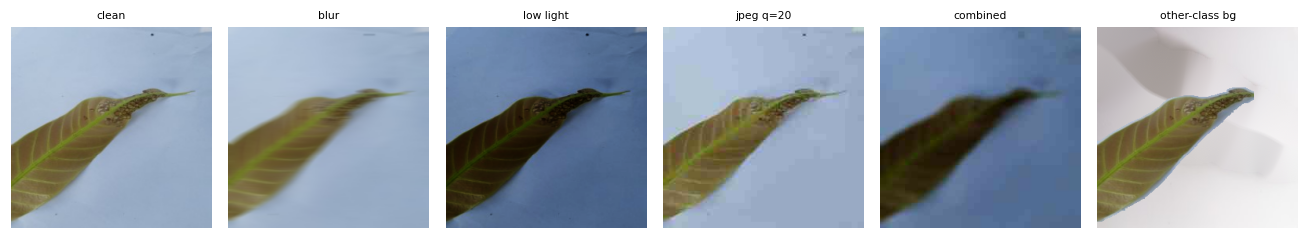

In [ ]:
# ----- 10.3 simulated field conditions -----
def low_light(img, gamma):
    return to_u8(255 * (img / 255.0) ** gamma)


def motion_blur(img, k):
    K = np.zeros((k, k), np.float32); K[k // 2] = 1.0 / k     # horizontal streak of length k
    return cv2.filter2D(img, -1, K)


def field_transform(img, kind, rng):
    if kind == "blur":
        return motion_blur(img, int(rng.choice([9, 15])))
    if kind == "low light":
        return low_light(img, rng.uniform(1.6, 2.4))
    if kind == "jpeg q=20":
        return jpeg(img, 20)
    if kind == "combined":
        out = field_transform(img, "low light", rng)
        out = cv2.filter2D(out, -1, np.ones((9, 9), np.float32) / 81)
        return jpeg(out, 30)


KINDS = ["blur", "low light", "jpeg q=20", "combined"]
rng_field = np.random.default_rng(41)
FIELD, FIELD_PRED = {}, {}
field_res = {"clean": eval_variant(IMGS[idx_te], idx_te)[0]}
for kind in KINDS:
    FIELD[kind] = np.stack([field_transform(IMGS[i], kind, rng_field) for i in idx_te])
    field_res[kind], FIELD_PRED[kind] = eval_variant(FIELD[kind], idx_te)
field_df = pd.DataFrame(field_res).T
print("Field shift stress test:")
print(field_df.round(3).to_string())

sens_field = tier_sensitivity(FIELD_PRED["combined"], yt)
print("\nTier-table sensitivity under 'combined' field conditions:")
print(sens_field.round(3).to_string())

fig, axs = plt.subplots(1, len(KINDS) + 2, figsize=(2 * (len(KINDS) + 2), 2.2))
show(axs[0], IMGS[idx_te[0]], "clean")
for k, kind in enumerate(KINDS):
    show(axs[k + 1], FIELD[kind][0], kind)
show(axs[-1], SWAP_CROSS[0] if len(SWAP_CROSS) else None, "other-class bg" if len(SWAP_CROSS) else None)
savefig("field_shift_examples")

---
## 11. Non-mango inputs and abstention *(feedback: what if the photo isn't a mango leaf?)*

**v1 problem.** OOD was tested on solid colours and noise (AUROC 1.000, which tells us nothing), while v1's own inference cells accepted a generic green leaf as *Healthy* at 0.9999992 confidence.

**v2**
- **Real near-OOD data:** leaves of *other* plants (default: a sample of PlantVillage via `kagglehub`; or set `MANGO_OOD_DIR` to any folder of non-mango leaf photos). Synthetic images are kept only as a trivial sanity check.
- **Two scores:** max softmax probability (MSP), and **kNN distance** in the network's penultimate features to the training set (Sun et al., 2022). Distance-based scores usually separate near-OOD inputs much better than MSP, which saturates at ~1.0 for an over-confident model.
- **Calibration set = validation photos, clean and under each simulated field condition (§10.3).** v2 used clean validation photos only. They are ~100% correct, so the temperature ran to the edge of its grid (confidence 1.0 on everything) and the thresholds rejected 97.5% of field-condition mango photos: the flag "rejected non-mango leaves" only because it rejected anything that was not a studio photo.
- **Thresholds are fixed on that calibration set** (accept 95% of it on each score), never on the test photos or the OOD data we report on.
- **We report acceptance per photo type** (clean, each field condition, each OOD set). A useful flag keeps most mango photos and rejects the OOD rows; the verdict table requires both.

In [ ]:
KNN_K = 10
knn_index = NearestNeighbors(n_neighbors=KNN_K).fit(l2n(F0[idx_tr]))


def knn_score(Fm):   # higher = more like the training data
    d, _ = knn_index.kneighbors(l2n(Fm))
    return -d[:, -1]


def msp(L):
    return softmax(L, TEMP).max(1)


def load_folder(path, n, rng):
    """Up to n readable images from a folder, in random order (None if there are none)."""
    files = [p for p in Path(path).rglob("*") if p.suffix.lower() in IMG_EXT]
    if not files:
        return None
    out = []
    for k in rng.permutation(len(files)):
        im = cv2.imread(str(files[k]))
        if im is not None:
            out.append(cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (IMG, IMG)))
        if len(out) >= n:
            break
    return np.stack(out) if out else None


rng_o = np.random.default_rng(51)
OOD_SETS = {}
syn = []
for _ in range(N_OOD // 2):
    syn.append(np.full((IMG, IMG, 3), rng_o.integers(0, 255, 3), np.uint8))
    syn.append(to_u8(rng_o.normal(128, 50, (IMG, IMG, 3))))
OOD_SETS["synthetic (solid / noise)"] = np.stack(syn)

real = None
if OOD_DIR and os.path.isdir(OOD_DIR):
    real = load_folder(OOD_DIR, N_OOD, rng_o)
elif kagglehub is not None:
    try:
        real = load_folder(kagglehub.dataset_download(OOD_KAGGLE), N_OOD, rng_o)
    except Exception as e:
        print(f"Could not download {OOD_KAGGLE}: {e}")
if real is not None:
    OOD_SETS["other-plant leaves"] = real
else:
    print("NO REAL OOD SET -- set MANGO_OOD_DIR to a folder of non-mango leaf photos. "
          "Without it, the OOD claim is untested; say so in the report.")

# ----- calibration set: validation photos, clean AND under each simulated field condition -----
# Clean validation photos alone are ~100% correct, which pushes the temperature to the edge of the grid
# (confidence = 1.0 for everything) and gives thresholds that reject every less-than-perfect photo.
rng_cal = np.random.default_rng(43)
cal = [(L0[idx_va], F0[idx_va])]
for kind in KINDS:
    cal.append(predict(model, np.stack([field_transform(IMGS[i], kind, rng_cal) for i in idx_va]), return_feats=True))
CAL_L = np.concatenate([L for L, _ in cal])
CAL_F = np.concatenate([Fm for _, Fm in cal])
CAL_Y = np.tile(Y[idx_va], len(cal))

# temperature scaling -- wide grid, and say so if it hits the edge
grid = np.exp(np.linspace(np.log(0.05), np.log(20), 120))
nll = [-np.log(softmax(CAL_L, T)[np.arange(len(CAL_Y)), CAL_Y] + 1e-12).mean() for T in grid]
TEMP = float(grid[int(np.argmin(nll))])
print(f"Temperature T = {TEMP:.3f} (fitted on {len(CAL_Y)} calibration photos; "
      f"model accuracy on them {(CAL_L.argmax(1) == CAL_Y).mean():.3f})")
if TEMP in (grid[0], grid[-1]):
    print("  NOTE: T is at the edge of the search grid -- calibration did not converge. "
          "Treat confidence as a ranking score, not a probability.")

# thresholds: accept the top 95% of the calibration photos on each score
THR_MSP = float(np.percentile(msp(CAL_L), 5))
THR_KNN = float(np.percentile(knn_score(CAL_F), 5))


def accept(L, Fm):
    return (msp(L) >= THR_MSP) & (knn_score(Fm) >= THR_KNN)


id_L, id_F = L0[idx_te], F0[idx_te]
print(f"Thresholds (5th pct of calibration photos): MSP >= {THR_MSP:.4f}, kNN >= {THR_KNN:.4f}")

rows = []
OOD_PRED = {}
for name, X in OOD_SETS.items():
    Lo, Fo = predict(model, X, return_feats=True)
    OOD_PRED[name] = (Lo, Fo)
    for sname, s_id, s_ood, thr in [("MSP", msp(id_L), msp(Lo), THR_MSP),
                                    ("kNN distance", knn_score(id_F), knn_score(Fo), THR_KNN)]:
        rows.append({"OOD set": name, "score": sname, "n": len(X),
                     "AUROC": roc_auc_score(np.r_[np.ones(len(s_id)), np.zeros(len(s_ood))], np.r_[s_id, s_ood]),
                     "OOD accepted": (s_ood >= thr).mean()})
    rows.append({"OOD set": name, "score": "combined policy", "n": len(X), "AUROC": np.nan,
                 "OOD accepted": accept(Lo, Fo).mean()})
OOD_TAB = pd.DataFrame(rows)
print("\n" + OOD_TAB.round(3).to_string(index=False))

if "other-plant leaves" in OOD_PRED:
    Lo, _ = OOD_PRED["other-plant leaves"]
    print("\nWhat the model calls other plants' leaves:",
          dict(Counter(str(CLASSES[k]) for k in Lo.argmax(1)).most_common()))


# ----- what does the accept / retake flag do to each kind of photo? -----
def acceptance_row(L, Fm, y=None):
    acc_ = accept(L, Fm)
    row = {"n": len(L), "accepted": acc_.mean()}
    if y is not None:
        right = L.argmax(1) == y
        row.update({"accuracy accepted": right[acc_].mean(), "accuracy flagged": right[~acc_].mean()})
    return row


ACCEPT_TAB = pd.DataFrame({
    "clean test": acceptance_row(id_L, id_F, yt),
    **{f"field: {k}": acceptance_row(*predict(model, FIELD[k], return_feats=True), yt) for k in KINDS},
    **{f"OOD: {name}": acceptance_row(*OOD_PRED[name]) for name in OOD_SETS},
}).T
print("\nAccept / retake flag by photo type (a useful flag accepts mango photos and rejects the OOD rows):")
print(ACCEPT_TAB.round(3).to_string())

Using Colab cache for faster access to the 'plantdisease' dataset.
Temperature T = 0.482 (fitted on 2930 calibration photos; model accuracy on them 0.965)
Thresholds (5th pct of calibration photos): MSP >= 0.7634, kNN >= -0.6984

                  OOD set           score   n  AUROC  OOD accepted
synthetic (solid / noise)             MSP 300  1.000         0.220
synthetic (solid / noise)    kNN distance 300  1.000         0.003
synthetic (solid / noise) combined policy 300    NaN         0.003
       other-plant leaves             MSP 300  0.865         0.817
       other-plant leaves    kNN distance 300  0.999         0.830
       other-plant leaves combined policy 300    NaN         0.767

What the model calls other plants' leaves: {'Bacterial Canker': 230, 'Healthy': 52, 'Powdery Mildew': 13, 'Sooty Mould': 2, 'Cutting Weevil': 1, 'Gall Midge': 1, 'Anthracnose': 1}

Accept / retake flag by photo type (a useful flag accepts mango photos and rejects the OOD rows):
                     

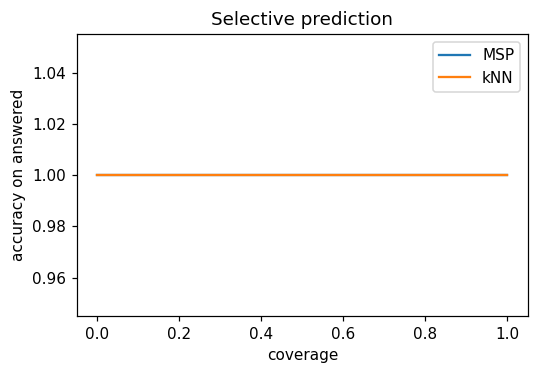

In [ ]:
# ----- selective prediction: accuracy vs coverage on the in-distribution test set -----
def risk_coverage(P, y, score):
    o = np.argsort(-score)
    corr = (P.argmax(1)[o] == y[o])
    n = np.arange(1, len(y) + 1)
    return n / len(y), np.cumsum(corr) / n


fig, ax = plt.subplots(figsize=(5, 3.5))
for nm, sc_ in [("MSP", msp(id_L)), ("kNN", knn_score(id_F))]:
    ax.plot(*risk_coverage(id_L, yt, sc_), label=nm)
ax.set_xlabel("coverage"); ax.set_ylabel("accuracy on answered"); ax.legend()
ax.set_title("Selective prediction")
savefig("risk_coverage")

---
## 12. Actionability: minimal photo-condition counterfactuals (Criterion 6)

The rubric asks for a counterfactual that changes only things the affected person can change.

| Immutable (nobody can change it) | Mutable (the farmer / officer can change it) |
|---|---|
| the leaf, its disease, lesion pattern, cultivar | **lighting** (shade vs daylight), **focus** (hand shake), **compression** (sending via a chat app), **background** (what the leaf is held against) |

So the counterfactual is about **the photo, not the leaf**: *"What is the smallest set of retake instructions that turns an unusable or wrong result into an accepted, correct-tier result?"*

**Protocol.** For `N_CF` test leaves we simulate a bad farmer photo with all four problems (other-class background, low light, motion blur, JPEG q=20). Then we try all 16 subsets of fixes and record the **smallest** subset whose output is *accepted by the §11 policy and in the correct triage tier*. The per-image parameters are fixed, so subsets are compared on the same photo.

The cell first prints **which requirement fails** (accept flag, tier, or both) for the bad photo and for the fully fixed photo, so a poor result is not read as a wrong label when it is the accept flag.

This turns into retake advice the officer can send to the farmer, and §13 adds simple photo-quality checks (brightness, sharpness, leaf size) that trigger it automatically.

**Why not v1's approach:** blurring the top 40% of Grad-CAM pixels is not a change anyone can make, and §8 shows the blur itself pushes predictions towards one class.

                               accepted  correct tier  both
bad photo (all four problems)     0.473         0.753  0.42
all four fixed                    1.000         1.000  1.00

150 simulated bad farmer photos
min_fix
none needed                            0.420
background                             0.213
focus                                  0.140
lighting                               0.093
background + focus                     0.060
compression                            0.033
background + compression               0.020
background + compression + lighting    0.007
focus + lighting                       0.007
background + lighting                  0.007

focus          0.673
compression    0.660
background     0.580
lighting       0.560


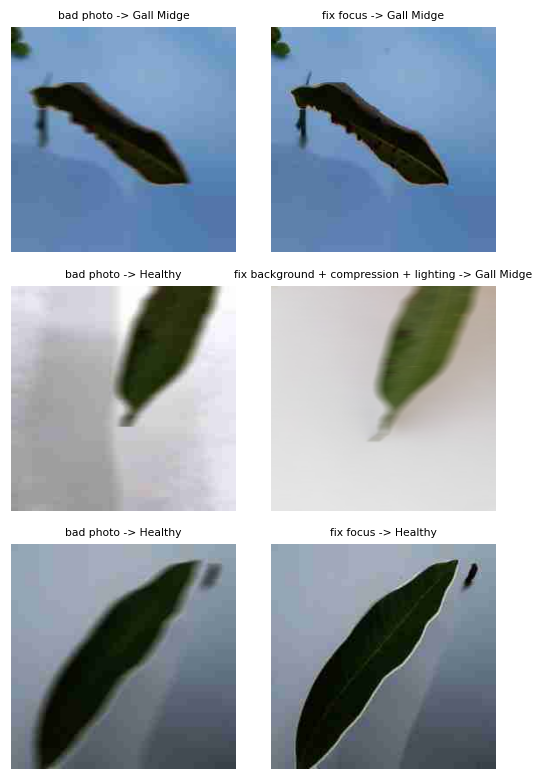

In [ ]:
FACTORS = ["background", "lighting", "focus", "compression"]
rng_cf = np.random.default_rng(61)
cf_idx = rng_cf.choice(sw_idx, min(N_CF, len(sw_idx)), replace=False)

# fixed "bad photo" parameters per image, so every subset of fixes is compared on the same photo
PRM = {}
for i in cf_idx:
    c_other = int(rng_cf.choice([c for c in DONORS if c != Y[i]]))
    PRM[i] = {"donor": rng_cf.choice(DONORS[c_other]), "gamma": rng_cf.uniform(1.6, 2.4),
              "k": int(rng_cf.choice([9, 15]))}


def render(i, problems):
    """Photo i with the given set of problems applied."""
    p = PRM[i]
    img = paste_leaf(i, donor_bg(p["donor"])) if "background" in problems else IMGS[i]
    if "lighting" in problems:
        img = low_light(img, p["gamma"])
    if "focus" in problems:
        img = motion_blur(img, p["k"])
    if "compression" in problems:
        img = jpeg(img, 20)
    return img


# all 16 subsets of fixes, smallest first
SUBSETS = [frozenset(s) for r in range(len(FACTORS) + 1) for s in itertools.combinations(FACTORS, r)]
meta = [(i, fix) for i in cf_idx for fix in SUBSETS]
Lb, Fb = predict(model, np.stack([render(i, set(FACTORS) - fix) for i, fix in meta]), return_feats=True)
gate = accept(Lb, Fb)
tier_ok = tv[Lb.argmax(1)] == tv[Y[[i for i, _ in meta]]]
OK = dict(zip(meta, map(bool, gate & tier_ok)))     # a photo is usable if it is accepted AND in the correct tier

# which requirement fails? (so a poor result is not read as "wrong label" when it is the accept flag)
n_fixed = np.array([len(fix) for _, fix in meta])
CF_GATE = pd.DataFrame({
    name: {"accepted": gate[m].mean(), "correct tier": tier_ok[m].mean(), "both": (gate & tier_ok)[m].mean()}
    for name, m in [("bad photo (all four problems)", n_fixed == 0), ("all four fixed", n_fixed == len(FACTORS))]}).T
print(CF_GATE.round(3).to_string() + "\n")

rows = []
for i in cf_idx:
    found = next((fix for fix in SUBSETS if OK[(i, fix)]), None)    # first hit = smallest fix
    if found is None:
        rows.append({"img": i, "min_fix_size": np.nan, "min_fix": "no photo fix helps"})
    elif not found:
        rows.append({"img": i, "min_fix_size": 0, "min_fix": "none needed"})
    else:
        rows.append({"img": i, "min_fix_size": len(found), "min_fix": " + ".join(sorted(found))})
CF = pd.DataFrame(rows)
print(f"{len(cf_idx)} simulated bad farmer photos")
print(CF.min_fix.value_counts(normalize=True).round(3).to_string())

single = {f: np.mean([OK[(i, frozenset([f]))] for i in cf_idx]) for f in FACTORS}
CF_SINGLE = pd.Series(single, name="share fixed by this ONE change").sort_values(ascending=False)
print("\n" + CF_SINGLE.round(3).to_string())

# examples: bad photo -> minimal fix
ex = CF[CF.min_fix_size >= 1].head(3)
if len(ex):
    fig, axs = plt.subplots(len(ex), 2, figsize=(5, 2.4 * len(ex)), squeeze=False)
    for r, (_, row) in enumerate(ex.iterrows()):
        fix = set(row.min_fix.split(" + "))
        a_img, b_img = render(row.img, set(FACTORS)), render(row.img, set(FACTORS) - fix)
        pa, pb = predict(model, np.stack([a_img, b_img])).argmax(1)
        show(axs[r, 0], a_img, f"bad photo -> {CLASSES[pa]}")
        show(axs[r, 1], b_img, f"fix {row.min_fix} -> {CLASSES[pb]}")
    savefig("counterfactual_examples")

---
## 13. Decision-support output (what the officer sees)

The report combines the §11 acceptance policy with photo-quality checks. Thresholds are the 5th percentile of the **training** photos, so "too dark" means darker than 95% of the photos the model learned from. The heat map is captioned *"where to look first"*, not *"why"*, because §8 shows it is not a reliable account of the model's reasons.

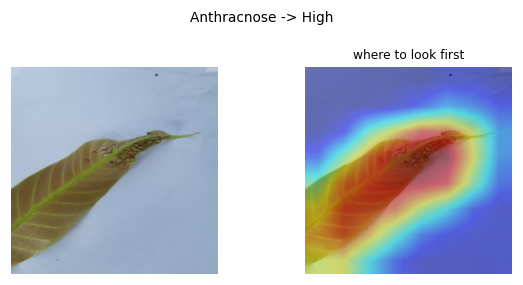

{'decision': 'Anthracnose', 'tier': 'High', 'confidence': 0.9996404647827148, 'knn_score': -0.37719088792800903, 'retake_advice': []}


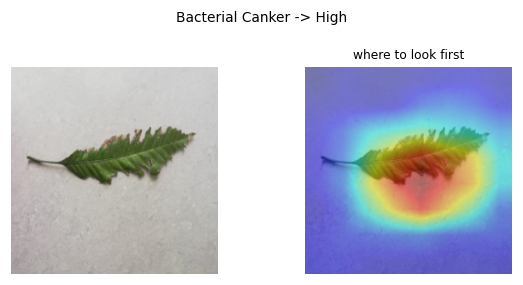

{'decision': 'Bacterial Canker', 'tier': 'High', 'confidence': 0.9999767541885376, 'knn_score': -0.3184206485748291, 'retake_advice': []}


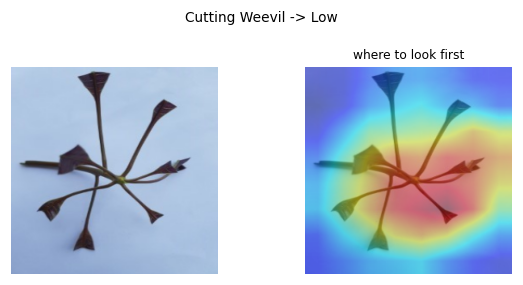

{'decision': 'Cutting Weevil', 'tier': 'Low', 'confidence': 0.9995300769805908, 'knn_score': -0.35345205664634705, 'retake_advice': ['move closer so the leaf fills the frame']}


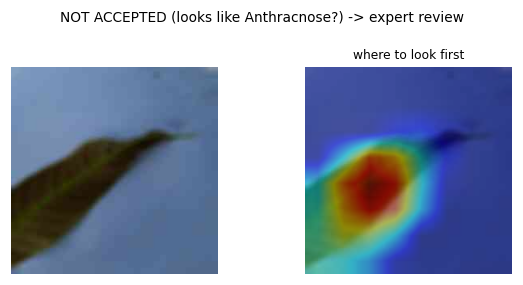

{'decision': 'NOT ACCEPTED (looks like Anthracnose?)', 'tier': 'expert review', 'confidence': 0.43478578329086304, 'knn_score': -0.7509222030639648, 'retake_advice': ['retake in daylight / out of shade', 'hold the phone steady and tap the leaf to focus']}


In [ ]:
def quality_stats(img):
    g = to_gray(img)
    return {"brightness": g.mean(), "sharpness": np.log1p(cv2.Laplacian(g, cv2.CV_32F).var()),
            "leaf_frac": leaf_mask(img).mean()}


QS = pd.DataFrame([quality_stats(IMGS[i]) for i in idx_tr])
Q_LOW = QS.quantile(0.05)
ADVICE = {"brightness": "retake in daylight / out of shade",
          "sharpness": "hold the phone steady and tap the leaf to focus",
          "leaf_frac": "move closer so the leaf fills the frame"}


def triage_report(img_u8, show_fig=True):
    """What the officer sees for one photo: label, tier, accept/retake flag and the heat map."""
    L, Fm = predict(model, img_u8[None], return_feats=True)
    P = softmax(L, TEMP)[0]
    c = int(P.argmax())
    ok_ = bool(accept(L, Fm)[0])
    q = quality_stats(img_u8)
    issues = [ADVICE[k] for k in ADVICE if q[k] < Q_LOW[k]]
    if ok_:
        decision = CLASSES[c]
    else:
        decision = f"NOT ACCEPTED (looks like {CLASSES[c]}?)"
        if not issues:
            issues = ["place the leaf on a plain, light surface and retake",
                      "if it is not a mango leaf, the system cannot assess it"]
    out = {"decision": decision, "tier": TRIAGE[CLASSES[c]] if ok_ else "expert review",
           "confidence": float(P.max()), "knn_score": float(knn_score(Fm)[0]), "retake_advice": issues}
    if show_fig:
        fig, ax = plt.subplots(1, 2, figsize=(5.5, 2.6))
        show(ax[0], img_u8)
        show(ax[1], overlay(img_u8, get_gradcam_maps(model, img_u8[None])[0]), "where to look first", fontsize=8)
        plt.suptitle(f"{decision} -> {out['tier']}", fontsize=9)
        plt.tight_layout(); plt.show()
    return out


for c in range(min(3, NC)):
    i = idx_te[np.where(Y[idx_te] == c)[0][0]]
    print(triage_report(IMGS[i]))
print(triage_report(FIELD["combined"][0]))

---
## 14. Ethics and data handling (Criterion 8)

### Data collection
- **MangoLeafBD** (Ahmed et al., 2023, *Data in Brief*), collected from four mango orchards in Bangladesh. We downloaded the Kaggle mirror `warcoder/mango-leaf-disease-dataset`; the original is on Mendeley Data. **TODO (team): confirm the licence on the original Mendeley page (we believe CC BY 4.0), cite its DOI, and check that the Kaggle mirror is identical.**
- **OOD leaves (§11):** PlantVillage via Kaggle (`emmarex/plantdisease`). **TODO: record its licence.** Used for evaluation only; images are not redistributed in our repository.
- **Photos downloaded from stock sites** for the v1 inference demo are **not** included in the repository or the report (licence restrictions).
- The images contain no people and no personal data, so no identifiers needed removing.

### Sensitive attributes and proxies
There are no protected attributes; the subjects are leaves. The rubric's question still applies in a different form: *which nuisance variables carry the label?* We measure them instead of asserting them:
- **Background** (photo surface) predicts the class on its own (§10.1), and replacing it moves predictions (§10.2).
- **Collection session** (the timestamp / near-duplicate groups) carries the label if the split ignores it (§2).
- **Geography / cultivar:** four Bangladeshi orchards only. We cannot measure this without other data; we state it as a limitation.

The cell below checks whether the interpretable baseline's top features are proxies for background, the same way one would check whether top credit features correlate with a protected attribute.

### Who could be harmed, and how the system limits it
- A **false "None/Low"** delays a visit to an infected farm. This is why §5 reports the missed-high rate and §12/§13 send unusable photos back for a retake instead of guessing.
- Farmers with older phones or no daylight access get more "retake" or "expert review" outcomes (§10.3, §12). The officer should not deprioritise those farms for that reason.
- The system is **decision support**; the officer makes the final call.

In [ ]:
bg_bright = XB[:, :3].mean(1)
top_feats = sorted({f for c in CLASSES for f in top_features(c, 3)})
PROXY = pd.DataFrame({f: {"Spearman with background brightness":
                          stats.spearmanr(X_HC[:, FEATURE_NAMES.index(f)], bg_bright)[0]} for f in top_feats}).T
PROXY = PROXY.sort_values("Spearman with background brightness", key=np.abs, ascending=False)
print("Top LR features vs background brightness (|rho| > 0.3 = likely proxy):")
print(PROXY.round(3).to_string())

Top LR features vs background brightness (|rho| > 0.3 = likely proxy):
                          Spearman with background brightness
b_std                                                  -0.366
b_mean                                                  0.302
V_std                                                  -0.285
frac_yellow                                             0.278
frac_green                                              0.267
texture_edge_density                                    0.258
a_mean                                                 -0.241
L_std                                                  -0.221
texture_laplacian_logvar                                0.216
H_mean                                                 -0.174
V_mean                                                 -0.151
frac_brown                                             -0.150
S_mean                                                  0.120
texture_gradient_mean                                   0.115

---
## 15. Human evidence: does Grad-CAM help a person catch the model's mistakes? (Criterion 5)

v1 asked raters whether a heat map "matches a symptom". That measures how much people *like* the map, and random blobs are easy to spot. The officer's real question is **"should I trust this label?"**, so v2 measures that directly.

**Design: error detection, within-subject, counterbalanced**
- **24 cases**, drawn from realistic hard photos (other-class backgrounds and combined field conditions from §10), so that **12 predictions are wrong and 12 are right**, with wrong and right cases each split evenly between the two photo sources (otherwise the kind of photo alone could give the answer away; the cell prints the breakdown). Correct and wrong cases look equally "hard", so photo quality alone doesn't give the answer away.
- The cases are split into halves H1 and H2 (6 wrong + 6 right each). **Form A** shows Grad-CAM on H1 and no heat map on H2; **Form B** does the reverse. Assign raters alternately to A and B, so every case is seen with and without the map.
- Each case shows the photo, predicted disease, tier and confidence. The rater answers: **Accept / Flag for expert review**, confidence 1–5, and an optional comment.
- Raters first read a one-page **reference sheet** (2 example photos per disease).
- **Sample:** aim for 6–10 classmates; people with farming experience are better. No significance tests at this scale.

**Outcome measures** (per condition): decision accuracy (flag wrong, accept right), **errors caught** (flag rate on wrong predictions), **false flags** (flag rate on right predictions), and per-rater difference with − without Grad-CAM.

**Record 2–3 things people say out loud** in the comment column, as the rubric asks. A null or negative result is a valid finding.

In [ ]:
hdir = OUT / "human_study"
for d_ in ["forms", "private"]:
    (hdir / d_).mkdir(parents=True, exist_ok=True)

# pool of realistic hard photos: (image, true y, predicted y, source)
pool = [(SWAP_CROSS[k], Y[i], PRED_CROSS[k], "other-class background") for k, i in enumerate(sw_idx)]
pool += [(FIELD["combined"][k], Y[i], FIELD_PRED["combined"][k], "field combined") for k, i in enumerate(idx_te)]
SOURCES = ["other-class background", "field combined"]
rng_h = np.random.default_rng(77)


def pick_cases(wrong, n):
    """n cases where the model is wrong (or right), half from each source, in alternating source order.
    Balancing matters: otherwise the kind of photo alone could tell a rater whether the label is wrong."""
    ids = [list(rng_h.permutation([k for k, p in enumerate(pool) if (p[1] != p[2]) == wrong and p[3] == s]))
           for s in SOURCES]
    chosen = [k for pair in zip(ids[0][:n // 2], ids[1][:n // 2]) for k in pair]
    spare = [k for src in ids for k in src if k not in chosen]     # used only if one source runs short
    return [int(k) for k in chosen + spare[:n - len(chosen)]]


n_each = min(12, sum(p[1] != p[2] for p in pool), sum(p[1] == p[2] for p in pool))
n_each -= n_each % 2
if n_each < 12:
    print(f"Only {n_each} wrong predictions available -- study will have {2 * n_each} cases.")
W, R = pick_cases(True, n_each), pick_cases(False, n_each)
half = n_each // 2
H1 = W[:half] + R[:half]      # Form A shows Grad-CAM on H1, Form B on H2
H2 = W[half:] + R[half:]
cases = H1 + H2
case_imgs = np.stack([pool[k][0] for k in cases])
case_pred = np.array([pool[k][2] for k in cases])
case_cams = get_gradcam_maps(model, case_imgs, targets=case_pred)
case_conf = softmax(predict(model, case_imgs), TEMP).max(1)
KEY = pd.DataFrame({
    "case_id": [f"C{j:02d}" for j in range(len(cases))],
    "true_class": [CLASSES[pool[k][1]] for k in cases],
    "predicted": [CLASSES[p] for p in case_pred],
    "model_wrong": [pool[k][1] != pool[k][2] for k in cases],
    "source": [pool[k][3] for k in cases],
    "cam_in_form_A": [j < len(H1) for j in range(len(cases))],
})
KEY.to_csv(hdir / "private" / "answer_key.csv", index=False)


def write_form(form):
    """One PDF page per case, in a random order; returns the case order."""
    order_ = rng_h.permutation(len(cases))
    with PdfPages(hdir / "forms" / f"form_{form}.pdf") as pdf:
        for j in order_:
            show_cam = KEY.cam_in_form_A[j] == (form == "A")
            fig, ax = plt.subplots(1, 2 if show_cam else 1, figsize=(8, 4.2), squeeze=False)
            show(ax[0, 0], case_imgs[j], "photo", fontsize=9)
            if show_cam:
                show(ax[0, 1], overlay(case_imgs[j], case_cams[j]), "where the model looked", fontsize=9)
            p_ = CLASSES[case_pred[j]]
            fig.suptitle(f"Case {KEY.case_id[j]} -- model says: {p_} (priority {TRIAGE[p_]}), "
                         f"confidence {case_conf[j]:.0%}\nAccept, or flag for expert review?  "
                         f"How sure are you (1-5)?", fontsize=10)
            pdf.savefig(fig); plt.close(fig)
    return [KEY.case_id[j] for j in order_]


order_A, order_B = write_form("A"), write_form("B")

with PdfPages(hdir / "forms" / "reference_sheet.pdf") as pdf:
    fig, axs = plt.subplots(NC, 2, figsize=(5, 2 * NC))
    for c in range(NC):
        ex_ = [i for i in idx_tr if Y[i] == c][:2]
        for k in range(2):
            show(axs[c, k], IMGS[ex_[k]] if k < len(ex_) else None)
        axs[c, 0].set_title(CLASSES[c], fontsize=9, loc="left")
    plt.tight_layout(); pdf.savefig(fig); plt.close(fig)

tmpl = [{"rater_id": "", "form": f, "case_id": cid, "decision_accept_or_flag": "",
         "confidence_1to5": "", "comment": ""} for f, od in [("A", order_A), ("B", order_B)] for cid in od]
pd.DataFrame(tmpl).to_csv(hdir / "responses_TEMPLATE.csv", index=False)
print(f"{len(cases)} cases ({KEY.model_wrong.sum()} wrong) -> {hdir / 'forms'}")
print(pd.crosstab([KEY.cam_in_form_A.map({True: "half 1", False: "half 2"}), KEY.source], KEY.model_wrong).to_string())
print("Give raters ONLY forms/ and the reference sheet. Keep private/answer_key.csv hidden.")

24 cases (12 wrong) -> /content/drive/MyDrive/XDS/mango_outputs_v2/human_study/forms
model_wrong                           False  True 
cam_in_form_A source                              
half 1        field combined              3      3
              other-class background      3      3
half 2        field combined              3      3
              other-class background      3      3
Give raters ONLY forms/ and the reference sheet. Keep private/answer_key.csv hidden.


In [ ]:
# ----- Analysis: run after filling human_study/responses.csv -----
resp_path = hdir / "responses.csv"
HUMAN = None
if resp_path.exists():
    Rr = pd.read_csv(resp_path).merge(KEY, on="case_id")
    Rr["shown_cam"] = np.where(Rr.form == "A", Rr.cam_in_form_A, ~Rr.cam_in_form_A.astype(bool))
    Rr["flag"] = Rr.decision_accept_or_flag.astype(str).str.lower().str.startswith("f")
    Rr["right_call"] = Rr.flag == Rr.model_wrong

    def summ(g):
        return pd.Series({"ratings": len(g), "decision accuracy": g.right_call.mean(),
                          "errors caught": g[g.model_wrong].flag.mean(),
                          "false flags": g[~g.model_wrong].flag.mean(),
                          "mean confidence": pd.to_numeric(g.confidence_1to5, errors="coerce").mean()})

    HUMAN = Rr.groupby("shown_cam").apply(summ).rename(index={True: "with Grad-CAM", False: "without"})
    print(f"Raters: {Rr.rater_id.nunique()} | ratings: {len(Rr)} (no significance claimed)")
    print(HUMAN.round(3).to_string())
    per_r = Rr.groupby(["rater_id", "shown_cam"]).right_call.mean().unstack()
    per_r["with - without"] = per_r.get(True) - per_r.get(False)
    print("\nPer rater:\n" + per_r.round(3).to_string())
    print("\nComments:")
    for _, r_ in Rr[Rr.comment.notna() & (Rr.comment.astype(str).str.strip() != "")].iterrows():
        print(f"  [{r_.rater_id}, {'CAM' if r_.shown_cam else 'no CAM'}, model {'wrong' if r_.model_wrong else 'right'}] {r_.comment}")
else:
    print(f"No responses yet. Fill {resp_path.name} (copy responses_TEMPLATE.csv) and re-run this cell.")

No responses yet. Fill responses.csv (copy responses_TEMPLATE.csv) and re-run this cell.


---
## 16. Related work

Saliency maps for plant disease are not new; our contribution is a **systematic test of whether they can be trusted for a triage decision**.
- Ahmed et al. (2023): MangoLeafBD dataset (*Data in Brief*)
- Brahimi et al. (2017): saliency-based symptom visualisation for tomato disease
- Toda & Okura (2019): how CNNs learn to diagnose plant disease
- Selvaraju et al. (2017): Grad-CAM
- Petsiuk et al. (2018): RISE; deletion/insertion evaluation
- Adebayo et al. (2018): Sanity Checks for Saliency Maps
- Adebayo et al. (2022): post-hoc explanations may be ineffective for detecting unknown spurious correlation (motivates §8.4)
- Hase & Bansal (2020): evaluating explanations by whether they help users predict model behaviour (motivates §15)
- Sun et al. (2022): out-of-distribution detection with deep nearest neighbours (§11)

**TODO (team):** add 1–2 papers that report accuracy on MangoLeafBD, to show how leakage-aware numbers compare.

---
## 17. Findings: verdict table

This cell builds the evidence table **from the numbers computed above**, so the report and the code cannot drift apart. The verdict rules are deliberately simple and are printed next to each row.

In [ ]:
def paired_row(kind, metric, null):
    r_ = PAIRED[(PAIRED.baseline == kind) & (PAIRED.metric == metric) & (PAIRED.null == null)].iloc[0]
    return f"{r_['GC advantage']:+.3f} [{r_['CI low']:+.3f}, {r_['CI high']:+.3f}]", r_.verdict


rows = []   # (claim, evidence, verdict)
rows.append(("Split removes near-duplicates",
             f"{len(gsz)} groups; v1 split leaked {leak_rate_old:.0%} of test; random split inflates acc ~{LEAK_INFLATION:.1f} pp",
             "check montages"))
rows.append(("Complex model is worth it", f"ResNet {RES_ACC:.3f} vs LR {cmp_df.test_acc.iloc[0]:.3f} ({GAP_PTS:.1f} pts)",
             "yes" if GAP_PTS > 2 else ("NO -- baseline is better" if GAP_PTS < -2 else "NO -- within 2 pts")))
for metric in ["deletion", "insertion"]:
    rows.append((f"Grad-CAM beats edge null on {metric}", *paired_row("blur", metric, "edge")))
corr_fc = float(sc.iloc[1, 1])
rows.append(("Grad-CAM depends on the model (randomisation)", f"corr after randomising fc = {corr_fc:.3f}",
             "yes" if corr_fc < 0.5 else "NO"))
rows.append(("Grad-CAM shows background reliance", f"Spearman {rho_gc:.3f} (edge null {rho_edge:.3f})",
             "yes" if rho_gc > max(0.3, rho_edge + 0.1) else "NO"))
if PATCH_TAB is not None:
    a_, b_ = PATCH_TAB.loc["Grad-CAM (patched model)", "pointing hit"], PATCH_TAB.loc["edge", "pointing hit"]
    rows.append(("Grad-CAM finds a planted shortcut", f"shortcut rate {SHORTCUT_RATE:.0%}; pointing GC {a_:.2f} vs edge {b_:.2f}",
                 "yes" if a_ > b_ + 0.1 else "NO / not better than edge"))
else:
    rows.append(("Grad-CAM finds a planted shortcut", f"shortcut rate {SHORTCUT_RATE:.0%}", "untested (too few flips)"))
seed_agree = SEED_STAB.loc["normalised agreement", "Spearman"]
rows.append(("Explanation stable across seeds", f"normalised Spearman {seed_agree:.2f}",
             "yes" if seed_agree > 0.5 else "partly"))
rows.append(("Explanation stable under small changes",
             f"min normalised Spearman {st_pert.normalised.min():.2f}" if len(st_pert) else "n/a",
             "yes" if len(st_pert) and st_pert.normalised.min() > 0.5 else "partly"))
acc_same, acc_cross = BG_TAB.loc["same-class background", "acc"], BG_TAB.loc["other-class background", "acc"]
rows.append(("Model does not rely on background",
             f"other-class bg acc {acc_cross:.3f} vs same-class {acc_same:.3f}; attraction {ATTRACTION:.0%}",
             "NO -- shortcut" if acc_same - acc_cross > 0.03 else "yes"))
missed_field = field_df.loc["combined", "missed_high"]
rows.append(("High-priority diseases are not missed under field conditions",
             f"missed-high rate {missed_field:.1%} (clean test {field_df.loc['clean', 'missed_high']:.1%})",
             "yes" if missed_field < 0.05 else "NO"))
field_ok = ACCEPT_TAB.loc["field: combined", "accepted"]
if "other-plant leaves" in OOD_PRED:
    ood_ok = ACCEPT_TAB.loc["OOD: other-plant leaves", "accepted"]
    rows.append(("Accept flag rejects non-mango leaves but keeps field photos",
                 f"{ood_ok:.0%} of non-mango leaves and {field_ok:.0%} of field-condition mango photos accepted",
                 "NO" if ood_ok >= 0.1 else ("yes" if field_ok >= 0.5 else "only by rejecting most field photos too")))
else:
    rows.append(("Accept flag rejects non-mango leaves but keeps field photos",
                 f"no real OOD set; {field_ok:.0%} of field-condition mango photos accepted", "untested"))
rows.append(("Retake advice is actionable", f"best single fix ({CF_SINGLE.index[0]}) rescues {CF_SINGLE.iloc[0]:.0%}", "see §12"))
if HUMAN is not None and {"with Grad-CAM", "without"} <= set(HUMAN.index):
    d_ = HUMAN.loc["with Grad-CAM", "errors caught"] - HUMAN.loc["without", "errors caught"]
    rows.append(("Grad-CAM helps people catch errors", f"errors caught {d_:+.2f} with Grad-CAM", "yes" if d_ > 0.1 else "no clear help"))
else:
    rows.append(("Grad-CAM helps people catch errors", "study not run yet", "pending"))
VERDICT = pd.DataFrame(rows, columns=["claim", "evidence", "verdict"])
pd.set_option("display.max_colwidth", 120)
print(VERDICT.to_string(index=False))

                                                       claim                                                                    evidence        verdict
                               Split removes near-duplicates 1850 groups; v1 split leaked 64% of test; random split inflates acc ~6.3 pp check montages
                                   Complex model is worth it                                          ResNet 1.000 vs LR 0.937 (6.3 pts)            yes
                        Grad-CAM beats edge null on deletion                                                     -0.023 [-0.033, -0.014]    null better
                       Grad-CAM beats edge null on insertion                                                     +0.065 [+0.056, +0.076]      GC better
               Grad-CAM depends on the model (randomisation)                                           corr after randomising fc = 0.062            yes
                          Grad-CAM shows background reliance                            

### How to write the conclusion
Write the claim the table supports, not the one we hoped for. If the rows come out as in v1, an honest version is:

> *Grad-CAM depends on the model (it fails the randomisation test as it should), but on deletion it is no more faithful than a model-free edge map, it localises lesions worse than one, and it does not reveal the model's reliance on photo backgrounds. For the field officer this means: use the heat map as "where to look first", never as the reason for the label, and trust the accept/retake flag more than the map.*

Then say what you would tell the officer in one sentence per finding (the rubric asks for this explicitly under stability).

---
## 18. Scope statement

| Claim | Supported by | Caveat |
|---|---|---|
| Accuracy on MangoLeafBD | near-duplicate-grouped split, per-class and tier metrics | four Bangladeshi orchards; grouping threshold is a judgement call (§2 montages) |
| Explanation is faithful | deletion/insertion vs nulls with CIs, randomisation, background reliance, planted patch | Grad-CAM only; two deletion baselines |
| Explanation is on lesions | dark-pixel proxy; human masks if the kit is completed | proxy invalid for Healthy, Die Back, Cutting Weevil, Powdery Mildew |
| Works on farmer photos | simulated field conditions and background swaps | no real farmer photos |
| Rejects non-mango input | other-plant leaves (if available), kNN + MSP | one OOD source |
| Helps the officer | error-detection study | small n, classmates rather than officers |

## 19. Model card (Criterion 9)

- **Model:** ResNet-50 (≈23.5M parameters once the 1000-class head is replaced by 8 classes; 50 layers, 53 conv layers) fine-tuned from ImageNet; AdamW (backbone 1e-4, head 1e-3), one-cycle, label smoothing 0.1, 12 epochs, best checkpoint by validation macro-F1; 3 seeds.
- **Intended use:** decision support for field officers triaging farmer leaf photos. Not an autonomous diagnostic tool; not validated outside the training orchards.
- **Training data:** MangoLeafBD (Ahmed et al., 2023), 4,000 photos, 8 classes; split by near-duplicate groups (§2), so no leaf appears in more than one split.
- **Evaluation:** `tables/` (classification, tier metrics, faithfulness, stability, background, field shift, OOD, counterfactuals, verdict).
- **Explanation:** Grad-CAM on `layer4[-1]`; see §17 for what it can and cannot be trusted for.
- **Confidence:** temperature-scaled on clean + simulated field-condition validation photos (§11); it is a ranking score, not a probability, for real farmer photos.
- **Known limitations:** background shortcut (§10); simulated field shift only; lesion proxy only partly validated; OOD tested on one other-plant dataset; triage tiers are expert judgement (sensitivity in §5.1, §10.3).
- **Reproducibility:** seeds listed in the config cell; versions in `requirements.txt`; checkpoints are keyed to the split hash; `papermill` regenerates every figure and table.
- **Licence:** code MIT; data per §14.

In [ ]:
TABLES = {
    "dup_threshold_sweep": sweep_df, "leakage": leak_df, "classification_comparison": cmp_df,
    "tier_sensitivity_clean": sens_clean, "tier_sensitivity_field": sens_field,
    "plausibility": PLAUS, "faithfulness_auc_blur": FA["blur"], "faithfulness_auc_grey": FA["grey"],
    "faithfulness_paired": PAIRED, "randomisation": sc, "background_faithfulness": BGF,
    "planted_patch": PATCH_TAB, "stability_seeds": SEED_STAB, "stability_perturbations": st_pert,
    "background_replacement": BG_TAB, "lr_vs_resnet_background": LR_ROBUST, "field_shift": field_df,
    "ood": OOD_TAB, "acceptance": ACCEPT_TAB, "split_threshold_sensitivity": SPLIT_SENS,
    "counterfactual_min_fix": CF, "counterfactual_single_fix": CF_SINGLE, "counterfactual_gate": CF_GATE,
    "background_proxy": PROXY, "human_study": HUMAN, "annotation_check": ANN, "verdict": VERDICT,
}
for name, obj in TABLES.items():
    if obj is not None:
        obj.to_csv(OUT / "tables" / f"{name}.csv")
print(f"{sum(o is not None for o in TABLES.values())} tables saved to {OUT / 'tables'}; figures in {OUT / 'figs'}")

25 tables saved to /content/drive/MyDrive/XDS/mango_outputs_v2/tables; figures in /content/drive/MyDrive/XDS/mango_outputs_v2/figs


---
## 20. Try it on your own photo
Off by default so that "Run all" never stops at an upload prompt: set `UPLOAD_DEMO = True` in the cell, or point `MANGO_INFER_DIR` at a folder.

Photos from stock-image sites are fine to *test* with, but don't commit them to the repository or put them in the report. **The cell output embeds the photo, so clear this cell's output before committing the notebook.**

In [ ]:
UPLOAD_DEMO = False     # set True in Colab to pick photos by hand; "Run all" then waits for the upload
INFER_DIR = os.environ.get("MANGO_INFER_DIR", "")
paths = []
if INFER_DIR:
    paths = [str(p) for p in Path(INFER_DIR).glob("*") if p.suffix.lower() in IMG_EXT]
elif IN_COLAB and UPLOAD_DEMO:
    from google.colab import files
    paths = list(files.upload().keys())
for fname in paths:
    print(f"\n--- {Path(fname).name} ---")
    print(triage_report(load_rgb(fname)))
if not paths:
    print("No photos given (set MANGO_INFER_DIR, or UPLOAD_DEMO = True in Colab).")

No photos given (set MANGO_INFER_DIR, or UPLOAD_DEMO = True in Colab).
